# Recommending recipes with Food.com data
**CSE 158 final project - Models and results**

Our EDA found three things that shape this notebook:
- Most users have reviewed only a few recipes.
- A small set of popular recipes gets most of the reviews.
- People tend to keep reviewing recipes with similar ingredients and tags.

Here we build models that use these facts and test how well they work.

**What we predict.** We know which recipes a user reviewed up to some date. We want to guess
which recipes they will review next. Each model gives every recipe a score, and we sort recipes
by that score to make a list for the user.

**What counts as "liked".** Any review counts as a sign of interest, whatever its star rating.
If a user never reviewed a recipe, we don't count that as a dislike. They may simply never have
seen it.

To run: put the two original CSV files in a folder called `dataset/`, then run all cells in order.

In [20]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

SEED = 158
DATA = Path('dataset')
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'figure.dpi': 110, 'font.size': 11, 'axes.spines.top': False,
                     'axes.spines.right': False, 'figure.constrained_layout.use': True})
COLORS = ['#187E89', '#E59143', '#7776A6']
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')

## 1. How do we test the models?

### Train on the past, test on the future
A real website can only use past reviews to guess future ones, so we test our models the same
way. We split the reviews by date:

| Part | Reviews from | What it's for |
|---|---|---|
| Training | before 2010 | models learn from these |
| Validation | 2010 | we try different settings and keep the best one |
| Test | 2011 | final scores (models relearn from all reviews before 2011) |

We don't split at random. A random split would let a model learn from reviews written *after*
the ones it is predicting, which is cheating.

### Why test on 2011 and not on recent years?
The EDA showed that by 2017, about 9 in 10 reviewers were reviewing for the first time. A model
can't personalize for someone it knows nothing about. In 2011 most reviewers had reviewed before,
and about a quarter of reviews were of recipes nobody had reviewed yet. That gives us enough of
both cases we care about.

### How we score a model
For each test review (a user and the recipe they reviewed), we mix the real recipe with
**100 random recipes** the user did not review. These must be recipes that already existed on
that date. The model scores all 101 and we see where the real recipe lands:

- **HR@10 (hit rate):** did the real recipe make the top 10? Random guessing gets about 10%.
- **NDCG@10:** like HR@10, but finishing 1st counts more than finishing 9th.
- **AUC:** what share of the 100 fake recipes did the real one beat? Random guessing gets 0.5,
  a perfect model gets 1.
- **MRR:** 1 divided by the real recipe's position (1st = 1, 2nd = 0.5, 10th = 0.1).

We use rankings instead of star-rating error because a website shows a short list. What matters
is whether the right recipe is near the top.

**Fairness rules:**
- If two recipes get exactly the same score, we order them at random.
- We use at most 5 test reviews per user.
- We average each user's scores first, then average across users, so very active users don't
  outweigh everyone else.

### Who we test
Only users who wrote at least one review before the test period. For someone with no history,
the only option is to show popular recipes, so they can't help us compare personalized models.

### Two kinds of recipes
We always report results separately for:
- **Warm recipes:** already had at least one review before the test period.
- **Cold recipes:** had no reviews yet. Models that rely on past reviews know nothing about these.

Our main idea is that a recipe's ingredients and tags can help with cold recipes, so this split
is the key result.

### Checking that the setup works
A model that guesses at random should score AUC ≈ 0.5 and HR@10 ≈ 10%. We check this below.
When we compare two models, we also give a 95% range for the difference. If that range doesn't
include zero, the difference is probably real and not just luck.

In [21]:
raw_recipes = pd.read_csv(DATA / 'RAW_recipes.csv')
raw_reviews = pd.read_csv(DATA / 'RAW_interactions.csv')

# Order the catalog by submission date, so "recipes available on day d" is a prefix of the array.
recipes = (raw_recipes[['id', 'submitted']]
           .assign(submitted=lambda d: pd.to_datetime(d.submitted, format='%Y-%m-%d'))
           .sort_values(['submitted', 'id'], ignore_index=True))
n_recipes = len(recipes)
recipe_pos = pd.Series(np.arange(n_recipes), index=recipes.id)
submitted_days = recipes.submitted.to_numpy(dtype='datetime64[ns]')

reviews = raw_reviews[['user_id', 'recipe_id', 'date', 'rating']].copy()
reviews['date'] = pd.to_datetime(reviews.date, format='%Y-%m-%d')
reviews['item'] = recipe_pos.reindex(reviews.recipe_id).to_numpy()
assert reviews.item.notna().all()
reviews['item'] = reviews.item.astype(np.int64)

# As in the EDA, drop reviews dated before the recipe was submitted.
valid = reviews.date.to_numpy(dtype='datetime64[ns]') >= submitted_days[reviews.item.to_numpy()]
dropped = int((~valid).sum())
reviews = reviews.loc[valid].reset_index(drop=True)
assert not reviews.duplicated(['user_id', 'item']).any()

TRAIN_END, VAL_END, TEST_END = map(pd.Timestamp, ['2010-01-01', '2011-01-01', '2012-01-01'])
train = reviews.loc[reviews.date.lt(TRAIN_END)]
val = reviews.loc[reviews.date.ge(TRAIN_END) & reviews.date.lt(VAL_END)]
train_val = reviews.loc[reviews.date.lt(VAL_END)]
test = reviews.loc[reviews.date.ge(VAL_END) & reviews.date.lt(TEST_END)]

def period_profile(history, period):
    known_user = period.user_id.isin(history.user_id.unique())
    cold_recipe = ~period.item.isin(history.item.unique())
    return {'Reviews': len(period), 'Users': period.user_id.nunique(),
            'Recipes': period.item.nunique(),
            'Reviews by known users (%)': known_user.mean() * 100,
            'Reviews of cold recipes (%)': cold_recipe.mean() * 100}

split_table = pd.DataFrame({'Validation (2010)': period_profile(train, val),
                            'Test (2011)': period_profile(train_val, test)}).T
display(split_table.style.format('{:,.1f}').format('{:,.0f}', subset=['Reviews', 'Users', 'Recipes']))
print(f'Dropped {dropped:,} reviews dated before recipe submission. '
      f'Train: {len(train):,} reviews; train + validation: {len(train_val):,} reviews.')

,Reviews,Users,Recipes,Reviews by known users (%),Reviews of cold recipes (%)
Validation (2010),"107,407","27,813","55,464",78.6,23.4
Test (2011),"72,140","21,763","42,968",76.8,23.8


Dropped 1,246 reviews dated before recipe submission. Train: 725,943 reviews; train + validation: 833,350 reviews.


- Training (before 2010) has **725,943 reviews**. The 2010 validation year has **107,407** and the
  2011 test year has **72,140**.
- About **77–79%** of reviews in each year come from users who had reviewed before. So most
  activity comes from returning users, which is what personalization needs.
- About **23–24%** of reviews in each year are of recipes with **no earlier reviews** (cold
  recipes). That's almost a quarter of all activity that review-based models know nothing about.
  This is the gap our content-based models aim to fill.
- We removed **1,246 reviews** dated before their recipe was posted, since those dates must be
  errors.

Validation and test look very similar, so choosing settings on 2010 should carry over well to 2011.

In [22]:
N_NEG, MAX_POS = 100, 5
HIST_BANDS = ['1', '2-4', '5-19', '20+']

def sample_negatives(n_available, seen, rng):
    """Draw N_NEG distinct recipes among the first n_available, skipping those in `seen`."""
    chosen = {}
    while len(chosen) < N_NEG:
        for item in rng.integers(n_available, size=2 * N_NEG).tolist():
            if item not in seen:
                chosen[item] = None
                if len(chosen) == N_NEG:
                    break
    return list(chosen)

def build_eval_set(history, period, seed):
    """Held-out positives from `period` for users seen in `history`, each with 100 negatives."""
    rng = np.random.default_rng(seed)
    hist_items = history.groupby('user_id').item.agg(set).to_dict()
    period_items = period.groupby('user_id').item.agg(set).to_dict()
    hist_counts = np.bincount(history.item.to_numpy(), minlength=n_recipes)

    pairs = period.loc[period.user_id.isin(hist_items.keys())].sample(frac=1, random_state=seed)
    pairs = pairs.loc[pairs.groupby('user_id').cumcount() < MAX_POS]
    pairs = pairs.sort_values(['user_id', 'date', 'item'], ignore_index=True)
    assert pairs.merge(history[['user_id', 'item']], on=['user_id', 'item']).empty

    # Negatives must already be submitted on the review date and unreviewed by the user.
    n_available = np.searchsorted(submitted_days, pairs.date.to_numpy(dtype='datetime64[ns]'),
                                  side='right')
    candidates = np.empty((len(pairs), N_NEG + 1), dtype=np.int64)
    candidates[:, 0] = pairs.item.to_numpy()          # column 0 is always the positive
    for row, (user, n_avail) in enumerate(zip(pairs.user_id.to_numpy(), n_available)):
        candidates[row, 1:] = sample_negatives(int(n_avail), hist_items[user] | period_items[user], rng)

    n_hist = pairs.user_id.map({u: len(s) for u, s in hist_items.items()})
    pairs = pairs.assign(warm=hist_counts[pairs.item.to_numpy()] > 0, n_hist=n_hist,
                         hist_band=pd.cut(n_hist, [0, 1, 4, 19, np.inf], labels=HIST_BANDS))
    return {'pairs': pairs, 'candidates': candidates}

val_set = build_eval_set(train, val, SEED)
test_set = build_eval_set(train_val, test, SEED + 1)

eval_summary = pd.DataFrame({
    name: {'Held-out reviews': len(s['pairs']), 'Users': s['pairs'].user_id.nunique(),
           'Cold recipes (%)': (~s['pairs'].warm).mean() * 100,
           **{f'History {b} (% users)': v * 100 for b, v in
              s['pairs'].groupby('user_id').hist_band.first().value_counts(normalize=True)
              .reindex(HIST_BANDS).items()}}
    for name, s in [('Validation', val_set), ('Test', test_set)]}).T
display(eval_summary)

,Held-out reviews,Users,Cold recipes (%),History 1 (% users),History 2-4 (% users),History 5-19 (% users),History 20+ (% users)
Validation,"31,150.0000","12,592.0000",15.2841,19.2741,24.3409,30.7973,25.5877
Test,"20,313.0000","8,994.0000",14.1486,17.3894,21.9813,30.9651,29.6642


- **Test:** 20,313 reviews from 8,994 returning users. **Validation:** 31,150 reviews from
  12,592 users.
- **About 14–15%** of test cases are cold recipes. That's lower than the 24% in the full year,
  most likely because we keep at most 5 reviews per user: very active users review many new
  recipes, and the cap removes most of those.
- History length is well spread. In the test set, **17%** of users have only 1 earlier review,
  **22%** have 2–4, **31%** have 5–19 and **30%** have 20 or more. This lets us check whether
  models improve as they learn more about a user.

In [23]:
METRICS = ['AUC', 'HR@10', 'NDCG@10', 'MRR']
SEGMENTS = {'All': lambda r: np.ones(len(r), dtype=bool),
            'Warm items': lambda r: r.warm.to_numpy(),
            'Cold items': lambda r: ~r.warm.to_numpy()}

def evaluate(score_fn, eval_set, seed=SEED):
    """score_fn(pairs, candidates) -> array of scores with candidates' shape (higher = better)."""
    pairs, candidates = eval_set['pairs'], eval_set['candidates']
    scores = np.asarray(score_fn(pairs, candidates), dtype=float)
    assert scores.shape == candidates.shape
    positive, negatives = scores[:, :1], scores[:, 1:]
    greater = (negatives > positive).sum(axis=1)
    ties = (negatives == positive).sum(axis=1)
    rank = greater + np.random.default_rng(seed).integers(0, ties + 1)   # 0 = top; random tie-break
    results = pairs[['user_id', 'warm', 'hist_band']].copy()
    results['AUC'] = 1 - (greater + 0.5 * ties) / N_NEG
    results['HR@10'] = (rank < 10).astype(float)
    results['NDCG@10'] = np.where(rank < 10, 1 / np.log2(rank + 2), 0.0)
    results['MRR'] = 1 / (rank + 1)
    return results

def summarize(results, model):
    """Average within users, then across users, for each item segment."""
    rows = []
    for segment, select in SEGMENTS.items():
        subset = results.loc[select(results)]
        per_user = subset.groupby('user_id')[METRICS].mean()
        rows.append({'model': model, 'segment': segment, 'users': len(per_user),
                     **per_user.mean().to_dict()})
    return pd.DataFrame(rows).set_index(['model', 'segment'])

def bootstrap_mean_ci(values, seed=SEED, repeats=1000):
    rng = np.random.default_rng(seed)
    means = []
    for start in range(0, repeats, 100):
        indexes = rng.integers(len(values), size=(min(100, repeats - start), len(values)))
        means.extend(values[indexes].mean(axis=1))
    return np.percentile(means, [2.5, 97.5])

def paired_difference(results_a, results_b, metric='HR@10'):
    """Mean per-user difference (A minus B) on the same eval set, with a 95% bootstrap interval."""
    a = results_a.groupby('user_id')[metric].mean()
    b = results_b.groupby('user_id')[metric].mean().reindex(a.index)
    difference = (a - b).to_numpy()
    low, high = bootstrap_mean_ci(difference)
    return difference.mean(), low, high

def random_scorer(pairs, candidates):
    return np.random.default_rng(SEED).random(candidates.shape)

# Validity check: a random ranking must match the theoretical values.
random_check = summarize(evaluate(random_scorer, val_set), 'Random').loc['Random']
display(random_check)
assert abs(random_check.loc['All', 'AUC'] - 0.5) < 0.02
assert abs(random_check.loc['All', 'HR@10'] - 10 / 101) < 0.02
print('Random scorer matches the expected AUC ≈ 0.5 and HR@10 ≈ 0.099.')

,users,AUC,HR@10,NDCG@10,MRR
segment,,,,,
All,12592,0.4991,0.0964,0.0436,0.0507
Warm items,11634,0.4981,0.0955,0.0436,0.0509
Cold items,3504,0.5053,0.1011,0.0451,0.0512


Random scorer matches the expected AUC ≈ 0.5 and HR@10 ≈ 0.099.


Random guessing gets **AUC = 0.499** (expected 0.5) and puts the real recipe in the top 10 for
**9.6%** of cases (expected 10 out of 101, about 9.9%). Warm and cold recipes give the same
result, as they should.

## 2. Model 1: Recommend the most popular recipes

**Question.** How well can we do if we show everyone the same list of popular recipes, with no
personalization at all?

**How it works.** Count how many reviews each recipe got before the cutoff date. Higher count
means higher score, and every user gets the same ranking.

**Why start here.** The EDA found the top 10% of recipes get over half of all reviews, so this
simple rule should already beat random guessing easily. It's also what we would show a brand-new
user. Every fancier model has to beat this one to be worth it.

**Three versions.** Tastes and trends change over time, so we try three ways of counting:
- **All-time:** count every review ever.
- **Recent only:** count only reviews from the last 30, 90, 180 or 365 days.
- **Fading:** count every review, but older reviews count for less. τ sets how fast old reviews
  fade: a small τ means only recent reviews matter much.

We pick the version that does best on 2010 (validation), then recount using all reviews before
2011 and test it on 2011.

The counts are made once at the cutoff date and not updated during the test year. All our
models follow this same rule, so the comparison is fair.

**What we expect to go wrong.** A recipe with no reviews yet has a count of 0, so it always ends
up below every recipe that has reviews. Popularity can never recommend a new recipe. Our later
models are meant to fix this.

In [24]:
def fit_popularity(history, end, window=None, tau=None):
    """Return one popularity score per recipe position, using only reviews before `end`."""
    age = (end - history.date).dt.days.to_numpy()
    if window is not None:
        weight = (age < window).astype(float)
    elif tau is not None:
        weight = np.exp(-age / tau)
    else:
        weight = np.ones(len(age))
    return np.bincount(history.item.to_numpy(), weights=weight, minlength=n_recipes)

def popularity_scorer(popularity):
    return lambda pairs, candidates: popularity[candidates]

POP_VARIANTS = ({'All-time count': {}}
                | {f'Last {w} days': {'window': w} for w in [30, 90, 180, 365]}
                | {f'Decay τ={t}d': {'tau': t} for t in [30, 90, 180, 365, 730]})

# Tune on validation: fit on train only, evaluate on 2010.
tuning = pd.concat([
    summarize(evaluate(popularity_scorer(fit_popularity(train, TRAIN_END, **params)), val_set), name)
    for name, params in POP_VARIANTS.items()
])
tuning_all = tuning.xs('All', level='segment')[METRICS].sort_values('NDCG@10', ascending=False)
display(tuning_all)
best_pop = tuning_all.index[0]
print(f'Best validation variant by NDCG@10: {best_pop}')

,AUC,HR@10,NDCG@10,MRR
model,,,,
Decay τ=730d,0.7510,0.5603,0.4023,0.3661
Decay τ=365d,0.7453,0.5509,0.3971,0.3623
All-time count,0.7436,0.5526,0.3928,0.3560
Decay τ=180d,0.7357,0.5261,0.3821,0.3508
Last 365 days,0.7503,0.5268,0.3816,0.3500
Decay τ=90d,0.7271,0.4914,0.3579,0.3317
Last 180 days,0.7273,0.4820,0.3548,0.3300
Last 90 days,0.6975,0.4462,0.3232,0.3002
Decay τ=30d,0.7186,0.4579,0.3122,0.2850


Best validation variant by NDCG@10: Decay τ=730d


- **Best: "Decay τ=730d".** Count every past review, but older reviews count for less.
  A review from yesterday counts fully, and a review from two years ago counts about a third
  as much. With this version, the recipe the user really reviewed shows up in the top 10
  for **56%** of users.
- **Close behind:** counting every review equally ("All-time count") gets **55%**.
  So giving newer reviews a bit more weight helps, but only a little.
- **Worst: counting only the last 30 days**, which gets **35%**. One month is too short.
  Many good recipes got no reviews that month, so they score 0 and drop off the list.

**In short:** recipes that have been popular for years are the best guess.
What was popular last month is a much worse guess.

In [25]:
# Final evaluation: refit on train + validation, evaluate once on 2011.
test_models = {
    'Random': random_scorer,
    'Popularity (all-time)': popularity_scorer(fit_popularity(train_val, VAL_END)),
    f'Popularity ({best_pop})': popularity_scorer(
        fit_popularity(train_val, VAL_END, **POP_VARIANTS[best_pop])),
}
test_results = {name: evaluate(fn, test_set) for name, fn in test_models.items()}
pop_table = pd.concat([summarize(res, name) for name, res in test_results.items()])
display(pop_table)

best_name = f'Popularity ({best_pop})'
comparisons = []
for a, b in [(best_name, 'Random'), (best_name, 'Popularity (all-time)')]:
    for metric in ['HR@10', 'NDCG@10']:
        mean, low, high = paired_difference(test_results[a], test_results[b], metric)
        comparisons.append({'comparison': f'{a} − {b}', 'metric': metric,
                            'difference': mean, '95% CI low': low, '95% CI high': high})
display(pd.DataFrame(comparisons).set_index(['comparison', 'metric']))

users    AUC  HR@10  NDCG@10    MRR
model                     segment                                        
Random                    All          8994 0.5028 0.1016   0.0467 0.0530
                          Warm items   8342 0.5026 0.1021   0.0471 0.0533
                          Cold items   2136 0.5029 0.0989   0.0440 0.0507
Popularity (all-time)     All          8994 0.7421 0.5402   0.3877 0.3540
                          Warm items   8342 0.8431 0.6132   0.4380 0.3981
                          Cold items   2136 0.0552 0.0000   0.0000 0.0105
Popularity (Decay τ=730d) All          8994 0.7536 0.5554   0.4000 0.3652
                          Warm items   8342 0.8574 0.6317   0.4525 0.4112
                          Cold items   2136 0.0552 0.0000   0.0000 0.0105

difference  \
comparison                                        metric                
Popularity (Decay τ=730d) − Random                HR@10        0.4539   
                                                  NDCG@10      0.3533   
Popularity (Decay τ=730d) − Popularity (all-time) HR@10        0.0152   
                                                  NDCG@10      0.0123   

                                                           95% CI low  \
comparison                                        metric                
Popularity (Decay τ=730d) − Random                HR@10        0.4441   
                                                  NDCG@10      0.3458   
Popularity (Decay τ=730d) − Popularity (all-time) HR@10        0.0107   
                                                  NDCG@10      0.0100   

                                                           95% CI high  
comparison                                        metric                
Popularity (Decay τ=730d) − Random                HR@10         0.4645  
                                                  NDCG@10       0.3607  
Popularity (Decay τ=730d) − Popularity (all-time) HR@10         0.0198  
                                                  NDCG@10       0.0146

**Overall:**
- Our best version puts the right recipe in the top 10 for **56%** of users.
- Random guessing does this for only **10%**.
- Counting all reviews equally gets **54%**, so our version is slightly better. The gap is
  small (about 1.5 points), but it holds up when we test it statistically, so it isn't luck.
- The 2011 score (56%) is about the same as the 2010 score, so the settings we picked
  work on new data too.

**Recipes with reviews vs. brand-new recipes.** This is the most important result:
- **Recipes that already had reviews:** the right recipe is in the top 10 for **63%** of
  users. Very good for such a simple method.
- **Brand-new recipes with no reviews:** **0%**, every single time. A new recipe has a count
  of zero, so it always lands at the bottom of the list. Here popularity does even worse than
  random guessing.

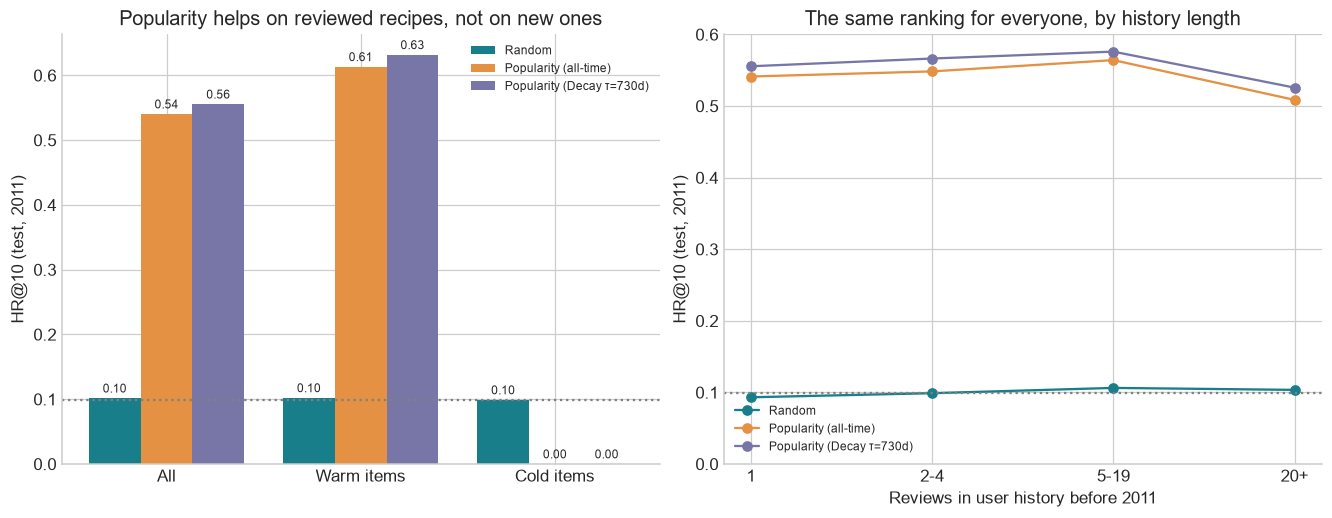

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))

# Left: HR@10 by item segment.
segments = list(SEGMENTS)
x = np.arange(len(segments))
width = 0.8 / len(test_results)
for k, (name, color) in enumerate(zip(test_results, COLORS)):
    values = pop_table.loc[name].reindex(segments)['HR@10']
    bars = axes[0].bar(x + (k - (len(test_results) - 1) / 2) * width, values, width,
                       label=name, color=color)
    axes[0].bar_label(bars, fmt='%.2f', padding=2, fontsize=8)
axes[0].axhline(10 / 101, ls=':', color='gray')
axes[0].set(xticks=x, xticklabels=segments, ylabel='HR@10 (test, 2011)',
            title='Popularity helps on reviewed recipes, not on new ones')
axes[0].legend(fontsize=8)

# Right: HR@10 by how much history the user has.
for name, color in zip(test_results, COLORS):
    per_user = test_results[name].groupby('user_id').agg(band=('hist_band', 'first'),
                                                         hr=('HR@10', 'mean'))
    by_band = per_user.groupby('band', observed=False).hr.mean().reindex(HIST_BANDS)
    axes[1].plot(HIST_BANDS, by_band, 'o-', color=color, label=name)
axes[1].axhline(10 / 101, ls=':', color='gray')
axes[1].set(xlabel='Reviews in user history before 2011', ylabel='HR@10 (test, 2011)',
            title='The same ranking for everyone, by history length', ylim=(0, None))
axes[1].legend(fontsize=8)
plt.show()

**Left chart: how often the right recipe makes the top 10.**
- Popularity (orange and purple bars) does far better than random guessing (teal bar),
  about 55–63% vs. 10%.
- But for brand-new recipes (right group), popularity drops to **zero**, below random
  guessing. It never recommends a new recipe.

**Right chart: does knowing more about a user help?**
- For popularity, the line is almost flat. Users with 1 past review and users with 19 get
  about the same result. That makes sense: popularity shows everyone the same list and
  ignores what they've reviewed before.
- It drops a little for the most active users (20+ reviews). They have probably already
  tried the most popular recipes, so what they pick next is less mainstream.

**Why this matters.** Popularity does worst on brand-new recipes and on our most active
users. Those are exactly the two places our next models, which learn each user's taste,
should help.

In [27]:
best = pop_table.loc[best_name]
alltime = pop_table.loc['Popularity (all-time)']
rand = pop_table.loc['Random']
gain_mean, gain_low, gain_high = paired_difference(test_results[best_name], test_results['Random'])

display(Markdown(f"""**Summary of Model 1: show everyone the most popular recipes**

**How well it works:**
- The right recipe makes the top 10 for **{best.loc['All', 'HR@10']:.0%}** of users.
- Random guessing manages only **{rand.loc['All', 'HR@10']:.0%}**.
- So this very simple method is about **{gain_mean * 100:.0f} points better** than guessing.

**Where it works and where it fails:**
- Recipes that already had reviews: **{best.loc['Warm items', 'HR@10']:.0%}**. Very good.
- Brand-new recipes with no reviews: **{best.loc['Cold items', 'HR@10']:.0%}**. It never
  recommends them, because a new recipe has a count of zero and always ends up last.

**Good points:** very fast, easy to build, and works even for users we know nothing about.

**Bad points:** everyone sees the same list, whatever they like, and new recipes never
get recommended.

**What our next models need to do:**
1. Beat **{best.loc['Warm items', 'HR@10']:.0%}** on recipes with reviews, by learning
   what each user likes.
2. Do better than zero on brand-new recipes, using ingredients and tags instead of
   review counts."""))

**Summary of Model 1: show everyone the most popular recipes**

**How well it works:**
- The right recipe makes the top 10 for **56%** of users.
- Random guessing manages only **10%**.
- So this very simple method is about **45 points better** than guessing.

**Where it works and where it fails:**
- Recipes that already had reviews: **63%**. Very good.
- Brand-new recipes with no reviews: **0%**. It never
  recommends them, because a new recipe has a count of zero and always ends up last.

**Good points:** very fast, easy to build, and works even for users we know nothing about.

**Bad points:** everyone sees the same list, whatever they like, and new recipes never
get recommended.

**What our next models need to do:**
1. Beat **63%** on recipes with reviews, by learning
   what each user likes.
2. Do better than zero on brand-new recipes, using ingredients and tags instead of
   review counts.

## 3. Model 2: Recommend recipes similar to ones the user already reviewed

**Question.** Can we beat popularity by using what each user reviewed before?

**The idea.** "People who reviewed this recipe also reviewed..." If many of the same people
reviewed two recipes, those recipes are probably similar in some way. So we recommend recipes
that are similar to the ones this user has already reviewed.

**How we measure "similar" (Jaccard similarity).** For two recipes A and B:

> similarity = (people who reviewed **both**) ÷ (people who reviewed **either one**)

Example: A was reviewed by 10 people and B by 6, and 4 people reviewed both. Then
similarity = 4 ÷ (10 + 6 − 4) = 4 ÷ 12 = 0.33. The score runs from 0 (no reviewers in common)
to 1 (exactly the same reviewers).

**Scoring a recipe for a user.** We compare the recipe with each recipe in the user's history
and combine the similarities in one of three ways:
- **max**: how close it is to the single most similar recipe they reviewed
- **mean**: how close it is to their history on average
- **sum**: like mean, but users with long histories get bigger scores (this doesn't change
  the order of one user's list)

We also try comparing against only the user's **10, 50 or 500 most recent** recipes, in case
recent taste matters more.

**Breaking ties with popularity.** Many recipes share no reviewers with anything the user
reviewed, so they all score exactly 0. We try two options for ordering these tied recipes:
randomly, or by popularity (the best version from Model 1). Popularity is used **only** to
order recipes with exactly the same similarity score.

As before, we pick the best settings on 2010 and test once on 2011.

**What we expect.** It should beat popularity on recipes that already have reviews, because it
uses each user's own history. It should still fail on brand-new recipes: nobody has reviewed
them, so they share no reviewers with anything and always score 0.

In [28]:
from scipy import sparse

HIST_CAPS = [10, 50, 500]            # how many of the user's most recent recipes to compare with
AGGREGATIONS = ['max', 'mean', 'sum']

def jaccard_scores(history, eval_set):
    """Jaccard scores for every candidate, for every (history cap, aggregation) setting at once."""
    pairs, candidates = eval_set['pairs'], eval_set['candidates']

    # Recipe-by-user table: row i marks the users who reviewed recipe i in the history.
    user_codes = history.user_id.astype('category').cat.codes.to_numpy()
    R = sparse.csr_matrix((np.ones(len(history), dtype=np.float32),
                           (history.item.to_numpy(), user_codes)),
                          shape=(n_recipes, user_codes.max() + 1))
    reviewers = np.asarray(R.getnnz(axis=1), dtype=np.float64)   # reviewers per recipe

    # Each test user's history, most recent recipe first.
    eval_history = history.loc[history.user_id.isin(pairs.user_id.unique())]
    recent = {user: group.item.to_numpy()[:max(HIST_CAPS)]
              for user, group in eval_history.sort_values(['date', 'item'], ascending=False)
                                             .groupby('user_id', sort=False)}

    scores = {(cap, agg): np.zeros(candidates.shape) for cap in HIST_CAPS for agg in AGGREGATIONS}
    for user, rows in pairs.groupby('user_id').indices.items():
        hist = recent[user]
        flat = candidates[rows].ravel()                               # all candidates of this user
        shared = (R[flat] @ R[hist].T).toarray().astype(np.float64)   # reviewers in common
        union = reviewers[flat][:, None] + reviewers[hist][None, :] - shared
        similarity = shared / union        # union >= 1: the user reviewed every history recipe
        for cap in HIST_CAPS:
            part = similarity[:, :cap]
            for agg in AGGREGATIONS:
                scores[(cap, agg)][rows] = getattr(part, agg)(axis=1).reshape(len(rows), -1)
    return scores

def with_popularity_tiebreak(scores, popularity, candidates):
    """Add a tiny popularity term: it only reorders recipes whose similarity scores are equal."""
    return scores + 1e-12 * popularity[candidates] / popularity.max()

In [29]:
# Choose settings on 2010: learn similarities from reviews before 2010 only.
val_jaccard = jaccard_scores(train, val_set)
val_popularity = fit_popularity(train, TRAIN_END, **POP_VARIANTS[best_pop])

tuning_rows = []
for (cap, agg), raw in val_jaccard.items():
    for tiebreak in ['no', 'yes']:
        final = (with_popularity_tiebreak(raw, val_popularity, val_set['candidates'])
                 if tiebreak == 'yes' else raw)
        result = summarize(evaluate(lambda p, c, f=final: f, val_set), 'tmp')
        tuning_rows.append({'Recent recipes used': cap, 'Combine by': agg,
                            'Popularity tie-break': tiebreak,
                            **result.xs('All', level='segment').iloc[0][METRICS].to_dict()})

jaccard_tuning = pd.DataFrame(tuning_rows).sort_values('NDCG@10', ascending=False, ignore_index=True)
display(jaccard_tuning)
best_cap = int(jaccard_tuning.loc[0, 'Recent recipes used'])
best_agg = jaccard_tuning.loc[0, 'Combine by']
print(f'Best settings on 2010: compare with the {best_cap} most recent recipes, combine by {best_agg}, '
      f'popularity tie-break = {jaccard_tuning.loc[0, "Popularity tie-break"]}.')

,Recent recipes used,Combine by,Popularity tie-break,AUC,HR@10,NDCG@10,MRR
0,500,sum,yes,0.7202,0.4457,0.2450,0.2031
1,500,mean,yes,0.7202,0.4457,0.2450,0.2031
2,50,mean,yes,0.7206,0.4434,0.2426,0.2009
3,50,sum,yes,0.7206,0.4434,0.2426,0.2009
4,10,sum,yes,0.7251,0.4512,0.2421,0.1982
5,10,mean,yes,0.7251,0.4512,0.2421,0.1982
6,10,max,yes,0.7199,0.4214,0.2110,0.1694
7,50,max,yes,0.7065,0.3717,0.1887,0.1568
8,500,max,yes,0.7015,0.3681,0.1874,0.1558
9,500,mean,no,0.6503,0.3332,0.1835,0.1576


Best settings on 2010: compare with the 500 most recent recipes, combine by sum, popularity tie-break = yes.


In [30]:
# Final test on 2011: relearn similarities from all reviews before 2011.
test_jaccard = jaccard_scores(train_val, test_set)
test_popularity = fit_popularity(train_val, VAL_END, **POP_VARIANTS[best_pop])
pure = test_jaccard[(best_cap, best_agg)]
jaccard_models = {
    'Jaccard (random tie-break)': pure,
    'Jaccard + popularity tie-break': with_popularity_tiebreak(pure, test_popularity,
                                                               test_set['candidates']),
}
for name, scores in jaccard_models.items():
    test_results[name] = evaluate(lambda p, c, s=scores: s, test_set)

shown = ['Random', best_name, *jaccard_models]
jaccard_table = pd.concat([summarize(test_results[name], name) for name, in zip(shown)])
display(jaccard_table)

# Is the improvement over popularity real? (95% ranges from 1,000 user resamples)
warm_mask = test_set['pairs'].warm.to_numpy()
comparison_rows = []
for label, mask in [('All recipes', np.ones(len(warm_mask), bool)), ('Recipes with reviews', warm_mask)]:
    for metric in ['HR@10', 'NDCG@10']:
        mean, low, high = paired_difference(test_results['Jaccard + popularity tie-break'][mask],
                                            test_results[best_name][mask], metric)
        comparison_rows.append({'test cases': label, 'metric': metric,
                                'Jaccard − popularity': mean, '95% low': low, '95% high': high})
display(pd.DataFrame(comparison_rows).set_index(['test cases', 'metric']))

# How often does the right recipe share no reviewers with anything in the user's history?
zero_right = pure[:, 0] == 0
zero_fake = (pure[:, 1:] == 0).mean()
print(f'Right recipe scores 0 in {zero_right.mean():.1%} of all test cases '
      f'({zero_right[warm_mask].mean():.1%} of recipes with reviews, '
      f'{zero_right[~warm_mask].mean():.1%} of brand-new recipes).')
print(f'{zero_fake:.1%} of the random "fake" recipes also score 0.')

users    AUC  HR@10  NDCG@10    MRR
model                          segment                                        
Random                         All          8994 0.5028 0.1016   0.0467 0.0530
                               Warm items   8342 0.5026 0.1021   0.0471 0.0533
                               Cold items   2136 0.5029 0.0989   0.0440 0.0507
Popularity (Decay τ=730d)      All          8994 0.7536 0.5554   0.4000 0.3652
                               Warm items   8342 0.8574 0.6317   0.4525 0.4112
                               Cold items   2136 0.0552 0.0000   0.0000 0.0105
Jaccard (random tie-break)     All          8994 0.6561 0.3369   0.1870 0.1614
                               Warm items   8342 0.6950 0.3788   0.2101 0.1790
                               Cold items   2136 0.3684 0.0255   0.0101 0.0245
Jaccard + popularity tie-break All          8994 0.7205 0.4367   0.2411 0.2013
                               Warm items   8342 0.8193 0.4953   0.2726 0.2262
                               Cold items   2136 0.0552 0.0000   0.0000 0.0105

Jaccard − popularity  95% low  95% high
test cases           metric                                          
All recipes          HR@10                 -0.1187  -0.1247   -0.1122
                     NDCG@10               -0.1589  -0.1642   -0.1538
Recipes with reviews HR@10                 -0.1365  -0.1435   -0.1291
                     NDCG@10               -0.1799  -0.1858   -0.1743

Right recipe scores 0 in 47.4% of all test cases (38.8% of recipes with reviews, 100.0% of brand-new recipes).
71.7% of the random "fake" recipes also score 0.


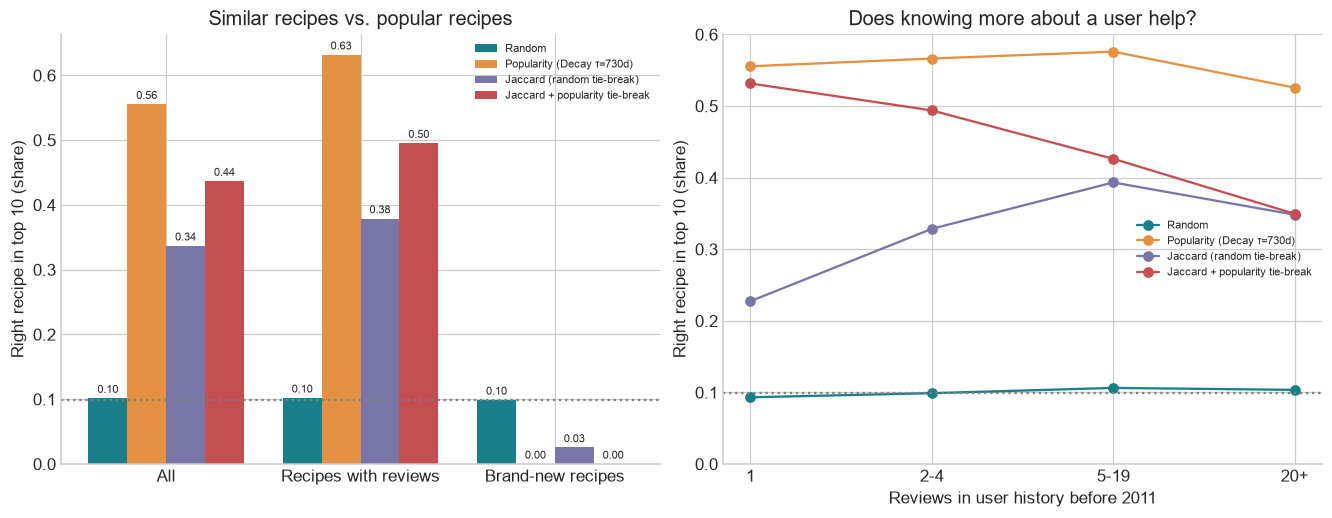

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
colors = COLORS + ['#C44E52']

# Left: top-10 hit rate by recipe type.
segments = list(SEGMENTS)
x = np.arange(len(segments))
width = 0.8 / len(shown)
for k, (name, color) in enumerate(zip(shown, colors)):
    values = jaccard_table.loc[name].reindex(segments)['HR@10']
    bars = axes[0].bar(x + (k - (len(shown) - 1) / 2) * width, values, width, label=name, color=color)
    axes[0].bar_label(bars, fmt='%.2f', padding=2, fontsize=7)
axes[0].axhline(10 / 101, ls=':', color='gray')
axes[0].set(xticks=x, xticklabels=['All', 'Recipes with reviews', 'Brand-new recipes'],
            ylabel='Right recipe in top 10 (share)', title='Similar recipes vs. popular recipes')
axes[0].legend(fontsize=7)

# Right: does a longer history help?
for name, color in zip(shown, colors):
    per_user = test_results[name].groupby('user_id').agg(band=('hist_band', 'first'),
                                                         hr=('HR@10', 'mean'))
    by_band = per_user.groupby('band', observed=False).hr.mean().reindex(HIST_BANDS)
    axes[1].plot(HIST_BANDS, by_band, 'o-', color=color, label=name)
axes[1].axhline(10 / 101, ls=':', color='gray')
axes[1].set(xlabel='Reviews in user history before 2011', ylabel='Right recipe in top 10 (share)',
            title='Does knowing more about a user help?', ylim=(0, None))
axes[1].legend(fontsize=7)
plt.show()

In [32]:
from IPython.display import display as show_output
from IPython.display import Markdown as MarkdownOutput

# Earlier model cells must have created jaccard_table.
if 'jaccard_table' not in globals():
    raise NameError(
        "Run the Jaccard evaluation cell first to create jaccard_table."
    )

jac = jaccard_table.loc['Jaccard + popularity tie-break']
jac_pure = jaccard_table.loc['Jaccard (random tie-break)']

# Find the selected popularity model.
model_names = jaccard_table.index.get_level_values(0).unique()

pop_name = (
    f'Popularity ({best_pop})'
    if 'best_pop' in globals()
    else globals().get('best_name')
)

if pop_name not in model_names:
    raise ValueError(
        "The selected popularity model is missing from jaccard_table. "
        "Run the popularity and Jaccard evaluation cells first."
    )

pop = jaccard_table.loc[pop_name]


def describe_difference(a, b):
    difference = (float(a) - float(b)) * 100

    if abs(difference) < 0.05:
        return "about the same"

    direction = "higher" if difference > 0 else "lower"
    return f"{abs(difference):.1f} percentage points {direction}"


def table_row(label, results):
    values = [
        f"{float(results.loc[segment, 'HR@10']):.1%}"
        for segment in ['All', 'Warm items', 'Cold items']
    ]
    return "| " + " | ".join([label] + values) + " |"


overall_difference = describe_difference(
    jac.loc['All', 'HR@10'],
    pop.loc['All', 'HR@10']
)

warm_difference = describe_difference(
    jac.loc['Warm items', 'HR@10'],
    pop.loc['Warm items', 'HR@10']
)

summary_text = "\n".join([
    "## Summary of Model 2: Recommend similar recipes",
    "",
    "**How often does the reviewed recipe appear in the top 10?**",
    "",
    "| Model | All recipes | Recipes with earlier reviews | Cold recipes |",
    "|---|---|---|---|",
    table_row("Popularity", pop),
    table_row("Jaccard with random tie-breaking", jac_pure),
    table_row("Jaccard with popularity tie-breaking", jac),
    "",
    f"- Compared with popularity, Jaccard with popularity tie-breaking "
    f"has an HR@10 that is **{overall_difference}** overall.",
    f"- For recipes with earlier reviews, its HR@10 is "
    f"**{warm_difference}**.",
    "",
    "**Why use popularity to break ties?**",
    "",
    "Many candidate recipes share no reviewers with the recipes in a "
    "user's history. They receive the same similarity score of zero. "
    "Popularity helps put these tied recipes in an order.",
    "",
    "**What works well?**",
    "",
    "Recommendations depend on the recipes each user reviewed. "
    "We can explain a recommendation by pointing to a recipe in "
    "that user's history.",
    "",
    "**What are the limits?**",
    "",
    "Recipes with few reviewers may have little overlap with other "
    "recipes. Cold recipes have no earlier reviewers, so their Jaccard "
    "similarities are all zero. They may appear through tie-breaking, "
    "but the model has no evidence that they match the user's interests.",
    "",
    "**What comes next?**",
    "",
    "BPR learns patterns across users' reviews. Later, a content-based "
    "model will use ingredients and tags to distinguish cold recipes."
])

show_output(MarkdownOutput(summary_text))

## Summary of Model 2: Recommend similar recipes

**How often does the reviewed recipe appear in the top 10?**

| Model | All recipes | Recipes with earlier reviews | Cold recipes |
|---|---|---|---|
| Popularity | 55.5% | 63.2% | 0.0% |
| Jaccard with random tie-breaking | 33.7% | 37.9% | 2.5% |
| Jaccard with popularity tie-breaking | 43.7% | 49.5% | 0.0% |

- Compared with popularity, Jaccard with popularity tie-breaking has an HR@10 that is **11.9 percentage points lower** overall.
- For recipes with earlier reviews, its HR@10 is **13.6 percentage points lower**.

**Why use popularity to break ties?**

Many candidate recipes share no reviewers with the recipes in a user's history. They receive the same similarity score of zero. Popularity helps put these tied recipes in an order.

**What works well?**

Recommendations depend on the recipes each user reviewed. We can explain a recommendation by pointing to a recipe in that user's history.

**What are the limits?**

Recipes with few reviewers may have little overlap with other recipes. Cold recipes have no earlier reviewers, so their Jaccard similarities are all zero. They may appear through tie-breaking, but the model has no evidence that they match the user's interests.

**What comes next?**

BPR learns patterns across users' reviews. Later, a content-based model will use ingredients and tags to distinguish cold recipes.

## 4. Model 3: Learn user and recipe preferences with BPR

**Question.** Can we improve on popularity and Jaccard by learning patterns across users' reviews?

**How it works.** BPR stands for Bayesian Personalized Ranking. It learns a list of numbers for each user and each recipe. The numbers are adjusted so that a user's reviewed recipes usually score higher than recipes they have not reviewed. They are learned from review patterns; they are not ingredient or tag features.

For example, if a user reviewed recipe A but not recipe B, training tries to give A a higher score for that user. B is a comparison recipe, not a confirmed dislike. We repeat this with many users, reviewed recipes, and randomly chosen comparison recipes.

**Recipe score.** We multiply the user's learned numbers by the recipe's learned numbers and add the products. We also learn a separate score for each recipe that can capture its general popularity.

**What we tune.** We try 32 or 64 numbers per user and recipe, two strengths of regularization, and 5, 10 or 20 training passes. Regularization limits how large the learned numbers become. We choose all settings using NDCG@10 on 2010 only, then train a fresh model on all reviews before 2011.

**Which recipes are used during training?** We sample comparison recipes only from recipes that already have reviews in the training history. We exclude recipes that the sampled user reviewed in that history. We never use validation or test reviews to choose training examples.

**Cold recipes.** A recipe with no training reviews gets a score of zero for every user. It can still appear above recipes with negative scores, but BPR cannot distinguish one cold recipe from another. Ingredients and tags will be needed to make different recommendations among those recipes.

The code below uses NumPy and SciPy, which are already used in this notebook. It keeps the existing date splits, sampled candidates, metrics, and equal weighting of users. It may take several minutes to train.

In [33]:
# NumPy BPR: no additional training library is required.
from scipy import sparse

class BPRModel:
    def __init__(self, history, n_items, factors=32, reg=0.01, learning_rate=0.02,
                 batch_size=512, seed=SEED):
        self.rng = np.random.default_rng(seed)
        self.users = pd.Index(history.user_id.unique())
        self.u_train = self.users.get_indexer(history.user_id).astype(np.int64)
        self.i_train = history.item.to_numpy(dtype=np.int64)
        self.active_items = np.unique(self.i_train)
        self.reg, self.learning_rate = reg, learning_rate
        self.batch_size = batch_size
        self.seen = sparse.csr_matrix(
            (np.ones(len(history), dtype=np.int8), (self.u_train, self.i_train)),
            shape=(len(self.users), n_items))
        self.user_factors = self.rng.normal(0, 0.05, (len(self.users), factors)).astype(np.float32)
        self.item_factors = np.zeros((n_items, factors), dtype=np.float32)
        self.item_factors[self.active_items] = self.rng.normal(
            0, 0.05, (len(self.active_items), factors)).astype(np.float32)
        self.item_bias = np.zeros(n_items, dtype=np.float32)
        # A user who reviewed every active recipe has no valid comparison recipe.
        eligible = np.asarray(self.seen.getnnz(axis=1)) < len(self.active_items)
        self.training_rows = np.flatnonzero(eligible[self.u_train])
        if not len(self.training_rows):
            raise ValueError('BPR needs users with at least one unreviewed training recipe.')

    def sample_comparisons(self, users):
        items = self.rng.choice(self.active_items, size=len(users))
        invalid = np.asarray(self.seen[users, items]).ravel() > 0
        while invalid.any():
            items[invalid] = self.rng.choice(self.active_items, size=int(invalid.sum()))
            invalid = np.asarray(self.seen[users, items]).ravel() > 0
        return items

    def train_epoch(self):
        total_loss, total_examples = 0.0, 0
        order = self.rng.permutation(self.training_rows)
        for start in range(0, len(order), self.batch_size):
            rows = order[start:start + self.batch_size]
            users, positive = self.u_train[rows], self.i_train[rows]
            negative = self.sample_comparisons(users)
            # Copies keep every gradient in this batch based on the same parameters.
            u = self.user_factors[users].copy()
            i = self.item_factors[positive].copy()
            j = self.item_factors[negative].copy()
            bi, bj = self.item_bias[positive].copy(), self.item_bias[negative].copy()
            difference = np.sum(u * (i - j), axis=1) + bi - bj
            gradient = np.exp(-np.logaddexp(0.0, difference))  # sigmoid(-difference)
            g = gradient[:, None]
            lr, reg = self.learning_rate, self.reg
            # add.at sums updates correctly when a user or recipe occurs twice in a batch.
            np.add.at(self.user_factors, users, lr * (g * (i - j) - reg * u))
            np.add.at(self.item_factors, positive, lr * (g * u - reg * i))
            np.add.at(self.item_factors, negative, lr * (-g * u - reg * j))
            np.add.at(self.item_bias, positive, lr * (gradient - reg * bi))
            np.add.at(self.item_bias, negative, lr * (-gradient - reg * bj))
            total_loss += float(np.logaddexp(0.0, -difference).sum())
            total_examples += len(rows)
        if not all(np.isfinite(a).all() for a in
                   [self.user_factors, self.item_factors, self.item_bias]):
            raise FloatingPointError('BPR diverged; reduce learning_rate.')
        return total_loss / total_examples

    def score(self, pairs, candidates):
        user_rows = self.users.get_indexer(pairs.user_id)
        scores = np.zeros(candidates.shape, dtype=np.float64)
        for start in range(0, len(pairs), 512):
            stop = min(start + 512, len(pairs))
            rows = user_rows[start:stop]
            known = rows >= 0
            user_vectors = np.zeros((stop - start, self.user_factors.shape[1]), dtype=np.float32)
            user_vectors[known] = self.user_factors[rows[known]]
            items = candidates[start:stop]
            scores[start:stop] = (np.einsum('bd,bkd->bk', user_vectors,
                                                    self.item_factors[items])
                                  + self.item_bias[items])
        return scores

In [34]:
# Choose settings using 2010 only. The test set is not used here.
BPR_CONFIGS = [{'factors': f, 'reg': r} for f in [32, 64] for r in [0.001, 0.01]]
BPR_CHECKPOINTS = [5, 10, 20]
bpr_tuning_rows = []
for config in BPR_CONFIGS:
    model = BPRModel(train, n_recipes, **config)
    for epoch in range(1, max(BPR_CHECKPOINTS) + 1):
        loss = model.train_epoch()
        print(f'{config}, epoch {epoch}: training ranking loss = {loss:.4f}', flush=True)
        if epoch in BPR_CHECKPOINTS:
            result = summarize(evaluate(model.score, val_set), 'BPR')
            metrics = result.loc[('BPR', 'All'), METRICS].to_dict()
            bpr_tuning_rows.append({**config, 'epochs': epoch, 'training loss': loss, **metrics})
    del model

bpr_tuning = pd.DataFrame(bpr_tuning_rows).sort_values(
    ['NDCG@10', 'factors', 'reg', 'epochs'],
    ascending=[False, True, True, True], ignore_index=True)
display(bpr_tuning)
bpr_choice = bpr_tuning.iloc[0]
best_bpr_config = {'factors': int(bpr_choice['factors']), 'reg': float(bpr_choice['reg'])}
best_bpr_epochs = int(bpr_choice['epochs'])
print(f'Chosen on validation: {best_bpr_config}, epochs={best_bpr_epochs}')

{'factors': 32, 'reg': 0.001}, epoch 1: training ranking loss = 0.6457
{'factors': 32, 'reg': 0.001}, epoch 2: training ranking loss = 0.5925
{'factors': 32, 'reg': 0.001}, epoch 3: training ranking loss = 0.5626
{'factors': 32, 'reg': 0.001}, epoch 4: training ranking loss = 0.5419
{'factors': 32, 'reg': 0.001}, epoch 5: training ranking loss = 0.5258
{'factors': 32, 'reg': 0.001}, epoch 6: training ranking loss = 0.5121
{'factors': 32, 'reg': 0.001}, epoch 7: training ranking loss = 0.4995
{'factors': 32, 'reg': 0.001}, epoch 8: training ranking loss = 0.4869
{'factors': 32, 'reg': 0.001}, epoch 9: training ranking loss = 0.4736
{'factors': 32, 'reg': 0.001}, epoch 10: training ranking loss = 0.4585
{'factors': 32, 'reg': 0.001}, epoch 11: training ranking loss = 0.4436
{'factors': 32, 'reg': 0.001}, epoch 12: training ranking loss = 0.4284
{'factors': 32, 'reg': 0.001}, epoch 13: training ranking loss = 0.4132
{'factors': 32, 'reg': 0.001}, epoch 14: training ranking loss = 0.3985
{

,factors,reg,epochs,training loss,AUC,HR@10,NDCG@10,MRR
0,64,0.0010,20,0.2982,0.8072,0.5574,0.3953,0.3594
1,32,0.0010,20,0.3246,0.8071,0.5574,0.3945,0.3584
2,32,0.0100,20,0.3843,0.8058,0.5553,0.3936,0.3579
3,64,0.0100,20,0.3578,0.8060,0.5549,0.3935,0.3580
4,64,0.0010,10,0.4429,0.8043,0.5518,0.3931,0.3585
5,64,0.0100,10,0.4733,0.8041,0.5515,0.3928,0.3583
6,32,0.0010,10,0.4585,0.8048,0.5534,0.3926,0.3573
7,32,0.0100,10,0.4808,0.8048,0.5532,0.3924,0.3571
8,32,0.0010,5,0.5258,0.8034,0.5510,0.3915,0.3567
9,32,0.0100,5,0.5286,0.8035,0.5509,0.3915,0.3567


Chosen on validation: {'factors': 64, 'reg': 0.001}, epochs=20


In [35]:
# Start again and train on all reviews before 2011, using the chosen settings.
bpr_model = BPRModel(train_val, n_recipes, **best_bpr_config)
for epoch in range(1, best_bpr_epochs + 1):
    loss = bpr_model.train_epoch()
    print(f'Final training, epoch {epoch}: ranking loss = {loss:.4f}', flush=True)

bpr_name = 'BPR'
test_results[bpr_name] = evaluate(bpr_model.score, test_set)
bpr_comparison_names = ['Random', best_name, 'Jaccard + popularity tie-break', bpr_name]
bpr_table = pd.concat([summarize(test_results[name], name) for name in bpr_comparison_names])
display(bpr_table)

bpr_differences = []
for reference in [best_name, 'Jaccard + popularity tie-break']:
    for segment, select in SEGMENTS.items():
        for metric in ['HR@10', 'NDCG@10']:
            a = test_results[bpr_name].loc[select(test_results[bpr_name])]
            b = test_results[reference].loc[select(test_results[reference])]
            if a.empty:
                continue
            difference, low, high = paired_difference(a, b, metric)
            bpr_differences.append({'reference': reference, 'segment': segment,
                                    'metric': metric, 'BPR minus reference': difference,
                                    '95% low': low, '95% high': high})
display(pd.DataFrame(bpr_differences).set_index(['reference', 'segment', 'metric']))

Final training, epoch 1: ranking loss = 0.6407
Final training, epoch 2: ranking loss = 0.5844
Final training, epoch 3: ranking loss = 0.5531
Final training, epoch 4: ranking loss = 0.5313
Final training, epoch 5: ranking loss = 0.5138
Final training, epoch 6: ranking loss = 0.4982
Final training, epoch 7: ranking loss = 0.4821
Final training, epoch 8: ranking loss = 0.4649
Final training, epoch 9: ranking loss = 0.4469
Final training, epoch 10: ranking loss = 0.4290
Final training, epoch 11: ranking loss = 0.4109
Final training, epoch 12: ranking loss = 0.3931
Final training, epoch 13: ranking loss = 0.3762
Final training, epoch 14: ranking loss = 0.3601
Final training, epoch 15: ranking loss = 0.3448
Final training, epoch 16: ranking loss = 0.3313
Final training, epoch 17: ranking loss = 0.3183
Final training, epoch 18: ranking loss = 0.3065
Final training, epoch 19: ranking loss = 0.2962
Final training, epoch 20: ranking loss = 0.2859


users    AUC  HR@10  NDCG@10    MRR
model                          segment                                        
Random                         All          8994 0.5028 0.1016   0.0467 0.0530
                               Warm items   8342 0.5026 0.1021   0.0471 0.0533
                               Cold items   2136 0.5029 0.0989   0.0440 0.0507
Popularity (Decay τ=730d)      All          8994 0.7536 0.5554   0.4000 0.3652
                               Warm items   8342 0.8574 0.6317   0.4525 0.4112
                               Cold items   2136 0.0552 0.0000   0.0000 0.0105
Jaccard + popularity tie-break All          8994 0.7205 0.4367   0.2411 0.2013
                               Warm items   8342 0.8193 0.4953   0.2726 0.2262
                               Cold items   2136 0.0552 0.0000   0.0000 0.0105
BPR                            All          8994 0.8069 0.5481   0.3916 0.3581
                               Warm items   8342 0.8235 0.6221   0.4425 0.4000
                               Cold items   2136 0.6572 0.0000   0.0000 0.0294

BPR minus reference  \
reference                      segment    metric                         
Popularity (Decay τ=730d)      All        HR@10                -0.0073   
                                          NDCG@10              -0.0084   
                               Warm items HR@10                -0.0097   
                                          NDCG@10              -0.0101   
                               Cold items HR@10                 0.0000   
                                          NDCG@10               0.0000   
Jaccard + popularity tie-break All        HR@10                 0.1114   
                                          NDCG@10               0.1504   
                               Warm items HR@10                 0.1268   
                                          NDCG@10               0.1699   
                               Cold items HR@10                 0.0000   
                                          NDCG@10               0.0000   

                                                   95% low  95% high  
reference                      segment    metric                      
Popularity (Decay τ=730d)      All        HR@10    -0.0118   -0.0028  
                                          NDCG@10  -0.0107   -0.0061  
                               Warm items HR@10    -0.0147   -0.0045  
                                          NDCG@10  -0.0129   -0.0074  
                               Cold items HR@10     0.0000    0.0000  
                                          NDCG@10   0.0000    0.0000  
Jaccard + popularity tie-break All        HR@10     0.1043    0.1183  
                                          NDCG@10   0.1453    0.1557  
                               Warm items HR@10     0.1189    0.1343  
                                          NDCG@10   0.1643    0.1756  
                               Cold items HR@10     0.0000    0.0000  
                                          NDCG@10   0.0000    0.0000

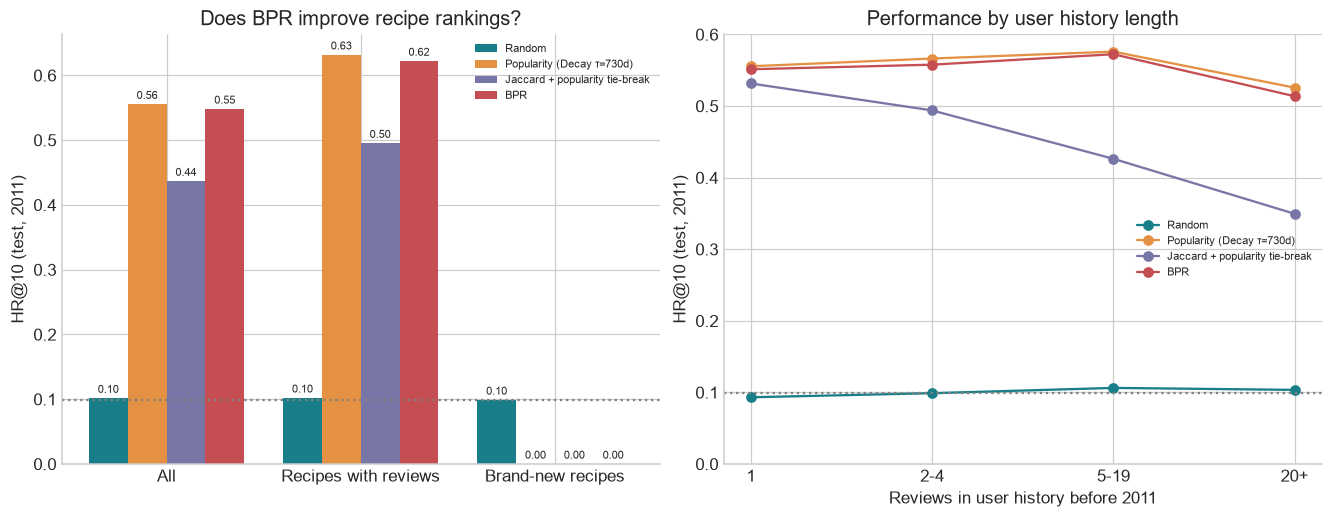

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
bpr_colors = ['#187E89', '#E59143', '#7776A6', '#C44E52']
segments = list(SEGMENTS)
x = np.arange(len(segments))
width = 0.8 / len(bpr_comparison_names)
for k, (name, color) in enumerate(zip(bpr_comparison_names, bpr_colors)):
    values = bpr_table.loc[name].reindex(segments)['HR@10']
    bars = axes[0].bar(x + (k - (len(bpr_comparison_names) - 1) / 2) * width,
                       values, width, label=name, color=color)
    axes[0].bar_label(bars, fmt='%.2f', padding=2, fontsize=7)
    per_user = test_results[name].groupby('user_id').agg(
        band=('hist_band', 'first'), hr=('HR@10', 'mean'))
    by_band = per_user.groupby('band', observed=False).hr.mean().reindex(HIST_BANDS)
    axes[1].plot(HIST_BANDS, by_band, 'o-', color=color, label=name)
axes[0].set(xticks=x, xticklabels=['All', 'Recipes with reviews', 'Brand-new recipes'],
            ylabel='HR@10 (test, 2011)', title='Does BPR improve recipe rankings?')
axes[1].set(xlabel='Reviews in user history before 2011', ylabel='HR@10 (test, 2011)',
            title='Performance by user history length', ylim=(0, None))
for ax in axes:
    ax.axhline(10 / 101, ls=':', color='gray')
    ax.legend(fontsize=7)
plt.show()

In [37]:
bpr_summary = bpr_table.loc[bpr_name]
summary_lines = [
    '**Summary of Model 3: learn user and recipe preferences with BPR**', '',
    f"- Chosen settings: **{best_bpr_config['factors']} numbers** per user and recipe, "
    f"regularization **{best_bpr_config['reg']}**, and **{best_bpr_epochs} training passes**.",
    f"- Overall HR@10: **{bpr_summary.loc['All', 'HR@10']:.1%}**.",
    f"- HR@10 for recipes with earlier reviews: **{bpr_summary.loc['Warm items', 'HR@10']:.1%}**.",
    f"- HR@10 for cold recipes: **{bpr_summary.loc['Cold items', 'HR@10']:.1%}**.",
]
for reference in [best_name, 'Jaccard + popularity tie-break']:
    difference, low, high = paired_difference(test_results[bpr_name], test_results[reference])
    evidence = ('The interval includes zero, so this comparison does not show a clear difference.'
                if low <= 0 <= high else
                'The interval is above zero, which supports an improvement in this evaluation.'
                if low > 0 else
                'The interval is below zero, which supports worse performance in this evaluation.')
    summary_lines.append(
        f'- Compared with {reference}, the HR@10 difference is **{difference * 100:+.2f} '
        f'percentage points** (95% interval: {low * 100:+.2f} to {high * 100:+.2f}). {evidence}')
summary_lines.extend(['',
    'BPR uses review patterns across users instead of comparing recipes only through shared reviewers. '
    'Its learned numbers can give two recipes a connection even when Jaccard similarity is zero.', '',
    '**Interpretation:** BPR is better suited to warm recipes because it learns personalized preferences '
    'from the full history of review patterns. Its improvement over Jaccard on earlier-reviewed recipes '
    'shows that latent factors can find useful connections beyond direct reviewer overlap. The small '
    'overall loss compared with popularity should be judged together with this warm-item gain.', '',
    'All cold recipes still get the same score of zero. Any hits on cold recipes do not mean the model '
    'learned their ingredients or tags. The next step is to use that recipe information.', '',
    'Each score comes from ranking one held-out reviewed recipe against 100 sampled alternatives. '
    'The results do not measure ranking against the entire recipe catalog.'])
display(Markdown('\n'.join(summary_lines)))

**Summary of Model 3: learn user and recipe preferences with BPR**

- Chosen settings: **64 numbers** per user and recipe, regularization **0.001**, and **20 training passes**.
- Overall HR@10: **54.8%**.
- HR@10 for recipes with earlier reviews: **62.2%**.
- HR@10 for cold recipes: **0.0%**.
- Compared with Popularity (Decay τ=730d), the HR@10 difference is **-0.73 percentage points** (95% interval: -1.18 to -0.28). The interval is below zero, which supports worse performance in this evaluation.
- Compared with Jaccard + popularity tie-break, the HR@10 difference is **+11.14 percentage points** (95% interval: +10.43 to +11.83). The interval is above zero, which supports an improvement in this evaluation.

BPR uses review patterns across users instead of comparing recipes only through shared reviewers. Its learned numbers can give two recipes a connection even when Jaccard similarity is zero.

**Interpretation:** BPR is better suited to warm recipes because it learns personalized preferences from the full history of review patterns. Its improvement over Jaccard on earlier-reviewed recipes shows that latent factors can find useful connections beyond direct reviewer overlap. The small overall loss compared with popularity should be judged together with this warm-item gain.

All cold recipes still get the same score of zero. Any hits on cold recipes do not mean the model learned their ingredients or tags. The next step is to use that recipe information.

Each score comes from ranking one held-out reviewed recipe against 100 sampled alternatives. The results do not measure ranking against the entire recipe catalog.

## 5. Model 4: Recommend recipes using ingredients and tags

**Question.** Can we recommend a recipe before anyone has reviewed it?

Popularity, Jaccard, and BPR depend on earlier reviews. Here, we use information inside the recipe itself.

**How it works.** Each recipe gets a list of ingredient and tag features. For example, a recipe might contain chicken and rice and have the tags "easy" and "weeknight."

We use TF-IDF to weight these features. Features found in many recipes receive less weight. Less common features receive more weight.

For each user, we average the features of recipes they previously reviewed. This creates a profile of the ingredients and tags in their review history. We compare each candidate recipe with that profile using cosine similarity. A higher score means a closer match.

**Example.** If a user often reviews recipes containing chicken and rice, another chicken-and-rice recipe may receive a high score. It does not need earlier reviews to receive that score.

**What we tune.**
- Ingredients only, tags only, or both.
- The user's 10, 50, or 500 most recent reviewed recipes.

We choose the settings with the highest validation NDCG@10 in 2010. Then we rebuild the model using information available before 2011 and evaluate it on the same test candidates as the earlier models.

**Avoiding future information.** We learn the feature vocabulary and TF-IDF weights only from recipes submitted before each cutoff. Later recipes can use those existing features, but they do not change the vocabulary or weights. User profiles use only reviews before the cutoff.

We assume the recorded ingredients and tags were available when each recipe was submitted. The dataset does not let us check whether these fields were edited later.

**Limitations.** Similar ingredients do not guarantee that a user will choose a recipe. A low-rated reviewed recipe also contributes to the profile because our task treats every review as an interaction. Recipes whose features were never seen before the cutoff may receive a score of zero.

In [38]:
import ast
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_extraction import DictVectorizer
from sklearn.feature_extraction.text import TfidfTransformer
from sklearn.preprocessing import normalize
from IPython.display import display as show_output
from IPython.display import Markdown as MarkdownOutput


def parse_recipe_list(value):
    """Convert a CSV list such as "['chicken', 'rice']" into a Python list."""
    if isinstance(value, (list, tuple)):
        return list(value)

    if pd.isna(value):
        return []

    parsed = ast.literal_eval(value)

    if not isinstance(parsed, (list, tuple)):
        raise ValueError(f"Expected a list, received: {value!r}")

    return list(parsed)


# Keep exactly the recipe order used by the earlier models.
content_metadata = (
    raw_recipes
    .set_index('id')
    .reindex(recipes.id.to_numpy())
)

assert len(content_metadata) == n_recipes

content_ingredients = (
    content_metadata['ingredients'].map(parse_recipe_list).tolist()
)

content_tags = (
    content_metadata['tags'].map(parse_recipe_list).tolist()
)


def make_feature_dicts(feature_type):
    """Keep each complete ingredient/tag as one feature."""
    documents = []

    for ingredients, tags in zip(content_ingredients, content_tags):
        features = {}

        if feature_type in ['ingredients', 'both']:
            for ingredient in ingredients:
                token = str(ingredient).strip().lower()
                if token:
                    features[f'ingredient:{token}'] = 1.0

        if feature_type in ['tags', 'both']:
            for tag in tags:
                token = str(tag).strip().lower()
                if token:
                    features[f'tag:{token}'] = 1.0

        documents.append(features)

    return documents


CONTENT_DOCUMENTS = {
    feature_type: make_feature_dicts(feature_type)
    for feature_type in ['ingredients', 'tags', 'both']
}


def fit_content_features(feature_type, cutoff):
    """Learn vocabulary and TF-IDF weights from the pre-cutoff catalog."""
    documents = CONTENT_DOCUMENTS[feature_type]

    available_before_cutoff = np.flatnonzero(
        recipes.submitted.lt(cutoff).to_numpy()
    )

    vectorizer = DictVectorizer(sparse=True, dtype=np.float32)

    # Later recipes must not influence the learned vocabulary.
    counts_before_cutoff = vectorizer.fit_transform(
        [documents[i] for i in available_before_cutoff]
    )

    tfidf = TfidfTransformer(norm='l2')
    tfidf.fit(counts_before_cutoff)

    # New recipes use the existing vocabulary and IDF weights.
    # Previously unseen ingredients/tags are ignored.
    all_counts = vectorizer.transform(documents)
    features = tfidf.transform(all_counts).tocsr()

    return features

In [39]:
CONTENT_HISTORY_CAPS = [10, 50, 500]


def content_scores(history, eval_set, features, history_cap):
    """Cosine similarity between candidate recipes and user profiles."""
    pairs = eval_set['pairs']
    candidates = eval_set['candidates']

    scores = np.zeros(candidates.shape, dtype=np.float64)

    # Only build histories for users included in this evaluation.
    relevant_history = history.loc[
        history.user_id.isin(pairs.user_id.unique())
    ]

    recent_items = {
        user: group.item.to_numpy(dtype=np.int64)[:history_cap]
        for user, group in (
            relevant_history
            .sort_values(['date', 'item'], ascending=False)
            .groupby('user_id', sort=False)
        )
    }

    for user, rows in pairs.groupby('user_id').indices.items():
        user_history = recent_items.get(user)

        if user_history is None or len(user_history) == 0:
            continue

        # Average the recipe vectors in the user's earlier reviews.
        profile = sparse.csr_matrix(
            features[user_history].mean(axis=0)
        )

        # A unit-length profile makes the dot product cosine similarity.
        profile = normalize(profile, norm='l2', axis=1)

        # Score only the candidates needed for this user.
        unique_items, inverse = np.unique(
            candidates[rows], return_inverse=True
        )

        unique_scores = (
            features[unique_items] @ profile.T
        ).toarray().ravel()

        scores[rows] = unique_scores[inverse].reshape(
            len(rows), candidates.shape[1]
        )

    assert np.isfinite(scores).all()
    return scores

In [40]:
from scipy import sparse

content_tuning_rows = []

for feature_type in ['ingredients', 'tags', 'both']:
    # Fit on recipes submitted before 2010.
    validation_features = fit_content_features(
        feature_type, TRAIN_END
    )

    for history_cap in CONTENT_HISTORY_CAPS:
        validation_scores = content_scores(
            train,
            val_set,
            validation_features,
            history_cap
        )

        validation_result = evaluate(
            lambda pairs, candidates, s=validation_scores: s,
            val_set
        )

        validation_summary = summarize(
            validation_result, 'Content'
        )

        overall = validation_summary.loc[('Content', 'All')]

        content_tuning_rows.append({
            'Features': feature_type,
            'Recent recipes used': history_cap,
            **overall[METRICS].to_dict(),
            'Cold HR@10': validation_summary.loc[
                ('Content', 'Cold items'), 'HR@10'
            ]
        })

    del validation_features

content_tuning = (
    pd.DataFrame(content_tuning_rows)
    .sort_values(
        ['NDCG@10', 'Features', 'Recent recipes used'],
        ascending=[False, True, True],
        ignore_index=True
    )
)

show_output(content_tuning)

best_content_type = content_tuning.loc[0, 'Features']
best_content_cap = int(
    content_tuning.loc[0, 'Recent recipes used']
)

print(
    f"Chosen on validation: {best_content_type}, "
    f"{best_content_cap} most recent reviewed recipes."
)

,Features,Recent recipes used,AUC,HR@10,NDCG@10,MRR,Cold HR@10
0,both,50,0.6463,0.2393,0.1249,0.1145,0.1504
1,both,500,0.6461,0.2389,0.1244,0.1140,0.1500
2,both,10,0.6417,0.2365,0.1231,0.1128,0.1620
3,ingredients,50,0.6109,0.2064,0.1050,0.0981,0.1619
4,ingredients,500,0.6109,0.2057,0.1044,0.0976,0.1595
5,ingredients,10,0.6050,0.2035,0.1038,0.0972,0.1662
6,tags,50,0.6051,0.1956,0.0973,0.0917,0.1638
7,tags,500,0.6049,0.1957,0.0971,0.0914,0.1615
8,tags,10,0.6003,0.1937,0.0969,0.0915,0.1683


Chosen on validation: both, 50 most recent reviewed recipes.


In [42]:
# Rebuild using the catalog and review history before 2011.
test_content_features = fit_content_features(
    best_content_type, VAL_END
)

test_content_scores = content_scores(
    train_val,
    test_set,
    test_content_features,
    best_content_cap
)

content_name = 'Content-based TF-IDF'

test_results[content_name] = evaluate(
    lambda pairs, candidates: test_content_scores,
    test_set
)

popularity_name = f'Popularity ({best_pop})'

# Include BPR if its evaluation has already been run.
content_comparison_names = [
    name
    for name in [
        popularity_name,
        'Jaccard + popularity tie-break',
        'BPR',
        content_name
    ]
    if name in test_results
]

content_table = pd.concat([
    summarize(test_results[name], name)
    for name in content_comparison_names
])

show_output(content_table)

# Compare the content model with earlier models using paired user scores.
content_comparisons = []

for reference in content_comparison_names:
    if reference == content_name:
        continue

    for segment, select in SEGMENTS.items():
        content_subset = test_results[content_name].loc[
            select(test_results[content_name])
        ]

        reference_subset = test_results[reference].loc[
            select(test_results[reference])
        ]

        if content_subset.empty:
            continue

        for metric in ['HR@10', 'NDCG@10']:
            difference, low, high = paired_difference(
                content_subset,
                reference_subset,
                metric
            )

            content_comparisons.append({
                'Reference': reference,
                'Segment': segment,
                'Metric': metric,
                'Content minus reference': difference,
                '95% low': low,
                '95% high': high
            })

content_comparison_table = (
    pd.DataFrame(content_comparisons)
    .set_index(['Reference', 'Segment', 'Metric'])
)

show_output(content_comparison_table)

users    AUC  HR@10  NDCG@10    MRR
model                          segment                                        
Popularity (Decay τ=730d)      All          8994 0.7536 0.5554   0.4000 0.3652
                               Warm items   8342 0.8574 0.6317   0.4525 0.4112
                               Cold items   2136 0.0552 0.0000   0.0000 0.0105
Jaccard + popularity tie-break All          8994 0.7205 0.4367   0.2411 0.2013
                               Warm items   8342 0.8193 0.4953   0.2726 0.2262
                               Cold items   2136 0.0552 0.0000   0.0000 0.0105
BPR                            All          8994 0.8069 0.5481   0.3916 0.3581
                               Warm items   8342 0.8235 0.6221   0.4425 0.4000
                               Cold items   2136 0.6572 0.0000   0.0000 0.0294
Content-based TF-IDF           All          8994 0.6394 0.2362   0.1225 0.1118
                               Warm items   8342 0.6511 0.2481   0.1291 0.1168
                               Cold items   2136 0.5595 0.1566   0.0768 0.0760

Content minus reference  \
Reference                      Segment    Metric                             
Popularity (Decay τ=730d)      All        HR@10                    -0.3192   
                                          NDCG@10                  -0.2775   
                               Warm items HR@10                    -0.3836   
                                          NDCG@10                  -0.3235   
                               Cold items HR@10                     0.1566   
                                          NDCG@10                   0.0768   
Jaccard + popularity tie-break All        HR@10                    -0.2005   
                                          NDCG@10                  -0.1186   
                               Warm items HR@10                    -0.2471   
                                          NDCG@10                  -0.1435   
                               Cold items HR@10                     0.1566   
                                          NDCG@10                   0.0768   
BPR                            All        HR@10                    -0.3119   
                                          NDCG@10                  -0.2690   
                               Warm items HR@10                    -0.3739   
                                          NDCG@10                  -0.3134   
                               Cold items HR@10                     0.1566   
                                          NDCG@10                   0.0768   

                                                   95% low  95% high  
Reference                      Segment    Metric                      
Popularity (Decay τ=730d)      All        HR@10    -0.3299   -0.3084  
                                          NDCG@10  -0.2856   -0.2693  
                               Warm items HR@10    -0.3942   -0.3728  
                                          NDCG@10  -0.3317   -0.3152  
                               Cold items HR@10     0.1420    0.1715  
                                          NDCG@10   0.0687    0.0851  
Jaccard + popularity tie-break All        HR@10    -0.2111   -0.1900  
                                          NDCG@10  -0.1256   -0.1118  
                               Warm items HR@10    -0.2578   -0.2358  
                                          NDCG@10  -0.1507   -0.1362  
                               Cold items HR@10     0.1420    0.1715  
                                          NDCG@10   0.0687    0.0851  
BPR                            All        HR@10    -0.3228   -0.3015  
                                          NDCG@10  -0.2771   -0.2613  
                               Warm items HR@10    -0.3847   -0.3631  
                                          NDCG@10  -0.3217   -0.3046  
                               Cold items HR@10     0.1420    0.1715  
                                          NDCG@10   0.0687    0.0851

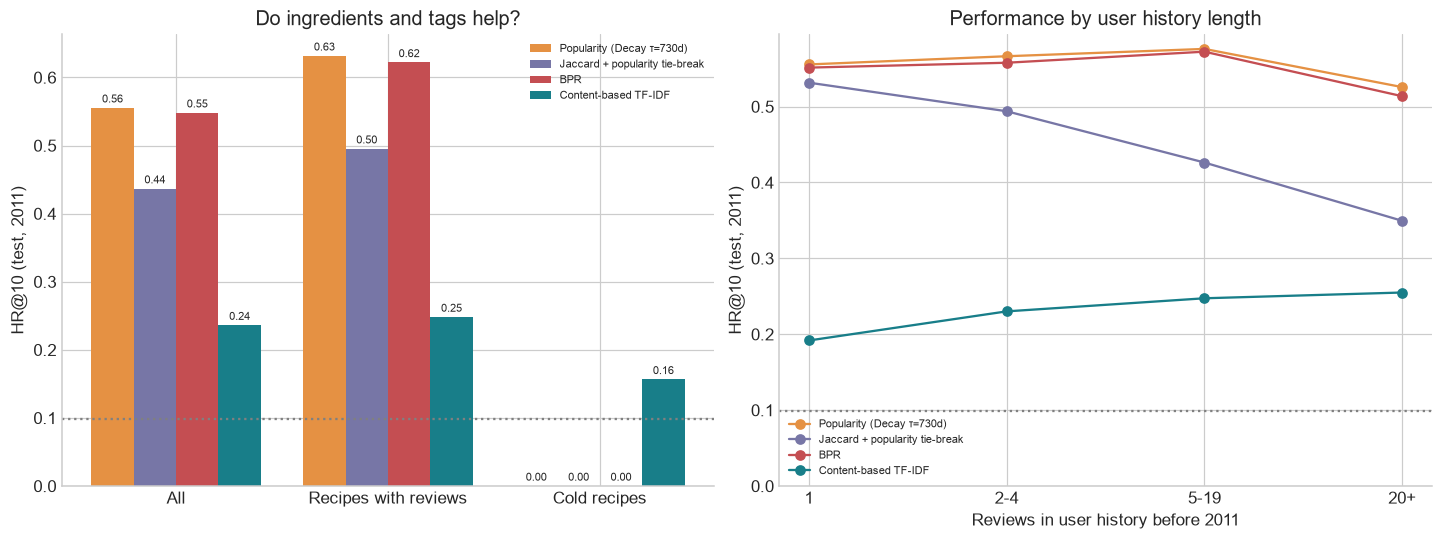

In [43]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

segments = list(SEGMENTS)
x = np.arange(len(segments))
width = 0.8 / len(content_comparison_names)

colors = ['#E59143', '#7776A6', '#C44E52', '#187E89']

for k, (name, color) in enumerate(
    zip(content_comparison_names, colors)
):
    values = (
        content_table.loc[name]
        .reindex(segments)['HR@10']
    )

    bars = axes[0].bar(
        x + (k - (len(content_comparison_names) - 1) / 2) * width,
        values,
        width,
        label=name,
        color=color
    )

    axes[0].bar_label(
        bars, fmt='%.2f', padding=2, fontsize=7
    )

    per_user = test_results[name].groupby('user_id').agg(
        band=('hist_band', 'first'),
        hr=('HR@10', 'mean')
    )

    by_band = (
        per_user.groupby('band', observed=False)
        .hr.mean()
        .reindex(HIST_BANDS)
    )

    axes[1].plot(
        HIST_BANDS, by_band, 'o-', label=name, color=color
    )

axes[0].set(
    xticks=x,
    xticklabels=['All', 'Recipes with reviews', 'Cold recipes'],
    ylabel='HR@10 (test, 2011)',
    title='Do ingredients and tags help?'
)

axes[1].set(
    xlabel='Reviews in user history before 2011',
    ylabel='HR@10 (test, 2011)',
    title='Performance by user history length',
    ylim=(0, None)
)

for ax in axes:
    ax.axhline(10 / 101, ls=':', color='gray')
    ax.legend(fontsize=7)

plt.show()

In [44]:
content_summary = content_table.loc[content_name]

summary_lines = [
    "## Summary of Model 4: Recommend using ingredients and tags",
    "",
    f"- Selected features: **{best_content_type}**.",
    f"- User profiles use up to **{best_content_cap}** recent reviews.",
    f"- Overall HR@10: **{content_summary.loc['All', 'HR@10']:.1%}**.",
    f"- HR@10 for recipes with earlier reviews: "
    f"**{content_summary.loc['Warm items', 'HR@10']:.1%}**.",
    f"- HR@10 for cold recipes: "
    f"**{content_summary.loc['Cold items', 'HR@10']:.1%}**.",
    "",
    "**Does it improve recommendations for cold recipes?**",
    ""
]

for reference in content_comparison_names:
    if reference == content_name:
        continue

    cold_content = test_results[content_name].loc[
        ~test_results[content_name].warm
    ]
    cold_reference = test_results[reference].loc[
        ~test_results[reference].warm
    ]

    if cold_content.empty:
        continue

    difference, low, high = paired_difference(
        cold_content, cold_reference, 'HR@10'
    )

    if low > 0:
        interpretation = (
            "The interval is above zero, supporting an improvement."
        )
    elif high < 0:
        interpretation = (
            "The interval is below zero, supporting worse performance."
        )
    else:
        interpretation = (
            "The interval includes zero, so the difference is not clear."
        )

    summary_lines.append(
        f"- Compared with **{reference}**, cold-recipe HR@10 changes by "
        f"**{difference * 100:+.2f} percentage points** "
        f"(95% interval: {low * 100:+.2f} to {high * 100:+.2f}). "
        f"{interpretation}"
    )

summary_lines.extend([
    "",
    "**What this model adds.** It can give different scores to recipes "
    "with no earlier reviews by comparing their ingredients and tags "
    "with the user's history.",
    "",
    "**What it misses.** Similar ingredients or tags do not capture "
    "everything that affects recipe choice. The model also does not "
    "learn which recipes are popular across other users.",
    "",
    "**What's next.** A hybrid model can combine review-based scores "
    "with content-based scores. Validation results should determine "
    "how much weight to give each.",
    "",
    "These results use one held-out reviewed recipe and 100 sampled "
    "alternatives per test case. They do not measure ranking against "
    "the entire catalog."
])

show_output(MarkdownOutput("\n".join(summary_lines)))

## Summary of Model 4: Recommend using ingredients and tags

- Selected features: **both**.
- User profiles use up to **50** recent reviews.
- Overall HR@10: **23.6%**.
- HR@10 for recipes with earlier reviews: **24.8%**.
- HR@10 for cold recipes: **15.7%**.

**Does it improve recommendations for cold recipes?**

- Compared with **Popularity (Decay τ=730d)**, cold-recipe HR@10 changes by **+15.66 percentage points** (95% interval: +14.20 to +17.15). The interval is above zero, supporting an improvement.
- Compared with **Jaccard + popularity tie-break**, cold-recipe HR@10 changes by **+15.66 percentage points** (95% interval: +14.20 to +17.15). The interval is above zero, supporting an improvement.
- Compared with **BPR**, cold-recipe HR@10 changes by **+15.66 percentage points** (95% interval: +14.20 to +17.15). The interval is above zero, supporting an improvement.

**What this model adds.** It can give different scores to recipes with no earlier reviews by comparing their ingredients and tags with the user's history.

**What it misses.** Similar ingredients or tags do not capture everything that affects recipe choice. The model also does not learn which recipes are popular across other users.

**What's next.** A hybrid model can combine review-based scores with content-based scores. Validation results should determine how much weight to give each.

These results use one held-out reviewed recipe and 100 sampled alternatives per test case. They do not measure ranking against the entire catalog.

## 6. Model 5: Combine popularity, BPR, and recipe content

**Question.** Can we keep the strong overall performance of review-based models while improving recommendations for cold recipes?

We combine three scores:
- **Popularity:** how often a recipe received reviews.
- **BPR:** how well the learned user and recipe preferences match.
- **Content:** how closely the ingredients and tags match the user's history.

These scores use different scales. Before combining them, we convert each model's scores into positions within the candidate list. Higher positions receive higher values. Recipes with equal scores remain tied.

The final score is:

> hybrid score = popularity weight × popularity score  
> + BPR weight × BPR score  
> + content weight × content score

The three weights add up to 1. We try weights in steps of 0.2 and choose the combination with the highest validation NDCG@10.

Every candidate uses the same formula. We do not tell the model which candidate the user actually reviewed.

Content can distinguish cold recipes using ingredients and tags. However, adding content does not guarantee better results. If validation chooses a content weight of zero, this combination did not benefit from content under our main scoring measure.

We choose weights using 2010 only, then apply those fixed weights to 2011. We report overall, warm-recipe, and cold-recipe results separately.

In [45]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import rankdata
from IPython.display import display as show_output
from IPython.display import Markdown as MarkdownOutput


def rank_scale(scores):
    """
    Convert each row's scores into values between 0 and 1.
    Equal scores receive equal values.
    This uses candidate scores only, not review labels.
    """
    scores = np.asarray(scores, dtype=np.float64)

    if scores.ndim != 2 or scores.shape[1] < 2:
        raise ValueError("Expected at least two candidates per row.")

    if not np.isfinite(scores).all():
        raise ValueError("Scores contain NaN or infinite values.")

    ranks = rankdata(scores, method='average', axis=1)
    return (ranks - 1) / (scores.shape[1] - 1)


def combine_hybrid(parts, weights):
    """Combine scores already converted by rank_scale."""
    return sum(
        weights[name] * parts[name]
        for name in ['popularity', 'bpr', 'content']
    )


# Popularity: use reviews before 2010.
hybrid_val_popularity = fit_popularity(
    train, TRAIN_END, **POP_VARIANTS[best_pop]
)

# BPR: train a separate validation model.
# Do not use bpr_model here: it was trained through 2010.
hybrid_val_bpr = BPRModel(
    train, n_recipes, **best_bpr_config
)

for epoch in range(1, best_bpr_epochs + 1):
    loss = hybrid_val_bpr.train_epoch()
    print(
        f"Validation BPR, epoch {epoch}/{best_bpr_epochs}: "
        f"loss = {loss:.4f}",
        flush=True
    )

# Content: rebuild the selected features using the pre-2010 catalog.
hybrid_val_features = fit_content_features(
    best_content_type, TRAIN_END
)

hybrid_val_content = content_scores(
    train,
    val_set,
    hybrid_val_features,
    best_content_cap
)

# All three arrays use exactly the same users and candidates.
hybrid_val_parts = {
    'popularity': rank_scale(
        hybrid_val_popularity[val_set['candidates']]
    ),
    'bpr': rank_scale(
        hybrid_val_bpr.score(
            val_set['pairs'], val_set['candidates']
        )
    ),
    'content': rank_scale(hybrid_val_content)
}

# Free objects no longer needed for tuning.
del hybrid_val_bpr, hybrid_val_features, hybrid_val_content

Validation BPR, epoch 1/20: loss = 0.6457
Validation BPR, epoch 2/20: loss = 0.5918
Validation BPR, epoch 3/20: loss = 0.5614
Validation BPR, epoch 4/20: loss = 0.5397
Validation BPR, epoch 5/20: loss = 0.5226
Validation BPR, epoch 6/20: loss = 0.5080
Validation BPR, epoch 7/20: loss = 0.4926
Validation BPR, epoch 8/20: loss = 0.4770
Validation BPR, epoch 9/20: loss = 0.4602
Validation BPR, epoch 10/20: loss = 0.4429
Validation BPR, epoch 11/20: loss = 0.4254
Validation BPR, epoch 12/20: loss = 0.4078
Validation BPR, epoch 13/20: loss = 0.3908
Validation BPR, epoch 14/20: loss = 0.3745
Validation BPR, epoch 15/20: loss = 0.3600
Validation BPR, epoch 16/20: loss = 0.3454
Validation BPR, epoch 17/20: loss = 0.3326
Validation BPR, epoch 18/20: loss = 0.3203
Validation BPR, epoch 19/20: loss = 0.3086
Validation BPR, epoch 20/20: loss = 0.2982


In [46]:
hybrid_tuning_rows = []

# Integer steps avoid floating-point problems when constructing weights.
# There are 21 combinations, including each model used alone.
for pop_step in range(6):
    for bpr_step in range(6 - pop_step):
        content_step = 5 - pop_step - bpr_step

        weights = {
            'popularity': pop_step / 5,
            'bpr': bpr_step / 5,
            'content': content_step / 5
        }

        scores = combine_hybrid(hybrid_val_parts, weights)

        results = evaluate(
            lambda pairs, candidates, s=scores: s,
            val_set
        )

        summary = summarize(results, 'Hybrid')

        hybrid_tuning_rows.append({
            **weights,
            **summary.loc[('Hybrid', 'All'), METRICS].to_dict(),
            'Warm HR@10': summary.loc[
                ('Hybrid', 'Warm items'), 'HR@10'
            ],
            'Cold HR@10': summary.loc[
                ('Hybrid', 'Cold items'), 'HR@10'
            ]
        })

# Use a fixed tie rule: prefer higher popularity weight,
# then higher BPR weight if validation NDCG@10 is identical.
hybrid_tuning = (
    pd.DataFrame(hybrid_tuning_rows)
    .sort_values(
        ['NDCG@10', 'popularity', 'bpr'],
        ascending=[False, False, False],
        ignore_index=True
    )
)

show_output(hybrid_tuning)

best_hybrid_weights = {
    name: float(hybrid_tuning.loc[0, name])
    for name in ['popularity', 'bpr', 'content']
}

print("Selected weights:", best_hybrid_weights)
print(
    "Validation NDCG@10:",
    round(float(hybrid_tuning.loc[0, 'NDCG@10']), 4)
)

,popularity,bpr,content,AUC,HR@10,NDCG@10,MRR,Warm HR@10,Cold HR@10
0,0.6000,0.4000,0.0000,0.7748,0.5661,0.4047,0.3676,0.6550,0.0000
1,0.8000,0.2000,0.0000,0.7567,0.5633,0.4037,0.3671,0.6522,0.0000
2,1.0000,0.0000,0.0000,0.7510,0.5603,0.4023,0.3661,0.6491,0.0000
3,0.4000,0.6000,0.0000,0.7956,0.5657,0.4012,0.3636,0.6544,0.0000
4,0.2000,0.8000,0.0000,0.8063,0.5623,0.3981,0.3612,0.6503,0.0000
5,0.0000,1.0000,0.0000,0.8072,0.5574,0.3953,0.3594,0.6444,0.0000
6,0.6000,0.2000,0.2000,0.7673,0.5564,0.3469,0.2969,0.6445,0.0000
7,0.4000,0.4000,0.2000,0.7908,0.5561,0.3469,0.2974,0.6439,0.0000
8,0.2000,0.6000,0.2000,0.8060,0.5519,0.3430,0.2946,0.6388,0.0000
9,0.8000,0.0000,0.2000,0.7538,0.5487,0.3418,0.2929,0.6359,0.0000


Selected weights: {'popularity': 0.6, 'bpr': 0.4, 'content': 0.0}
Validation NDCG@10: 0.4047


In [47]:
# Reuse the final BPR model and content scores from earlier sections.
# Both were built using history before 2011.
hybrid_test_popularity = fit_popularity(
    train_val, VAL_END, **POP_VARIANTS[best_pop]
)

hybrid_test_parts = {
    'popularity': rank_scale(
        hybrid_test_popularity[test_set['candidates']]
    ),
    'bpr': rank_scale(
        bpr_model.score(
            test_set['pairs'], test_set['candidates']
        )
    ),
    'content': rank_scale(test_content_scores)
}

hybrid_test_scores = combine_hybrid(
    hybrid_test_parts, best_hybrid_weights
)

hybrid_name = 'Hybrid: popularity + BPR + content'

test_results[hybrid_name] = evaluate(
    lambda pairs, candidates: hybrid_test_scores,
    test_set
)

hybrid_comparison_names = [
    f'Popularity ({best_pop})',
    'BPR',
    'Content-based TF-IDF',
    hybrid_name
]

hybrid_table = pd.concat([
    summarize(test_results[name], name)
    for name in hybrid_comparison_names
])

show_output(hybrid_table)

# Paired comparisons: same users and candidates for both models.
hybrid_difference_rows = []

for reference in hybrid_comparison_names[:-1]:
    for segment, select in SEGMENTS.items():
        hybrid_subset = test_results[hybrid_name].loc[
            select(test_results[hybrid_name])
        ]
        reference_subset = test_results[reference].loc[
            select(test_results[reference])
        ]

        if hybrid_subset.empty:
            continue

        for metric in ['HR@10', 'NDCG@10']:
            difference, low, high = paired_difference(
                hybrid_subset, reference_subset, metric
            )

            hybrid_difference_rows.append({
                'Reference': reference,
                'Segment': segment,
                'Metric': metric,
                'Hybrid minus reference': difference,
                '95% low': low,
                '95% high': high
            })

hybrid_difference_table = pd.DataFrame(
    hybrid_difference_rows
).set_index(['Reference', 'Segment', 'Metric'])

show_output(hybrid_difference_table)

users    AUC  HR@10  NDCG@10  \
model                              segment                                    
Popularity (Decay τ=730d)          All          8994 0.7536 0.5554   0.4000   
                                   Warm items   8342 0.8574 0.6317   0.4525   
                                   Cold items   2136 0.0552 0.0000   0.0000   
BPR                                All          8994 0.8069 0.5481   0.3916   
                                   Warm items   8342 0.8235 0.6221   0.4425   
                                   Cold items   2136 0.6572 0.0000   0.0000   
Content-based TF-IDF               All          8994 0.6394 0.2362   0.1225   
                                   Warm items   8342 0.6511 0.2481   0.1291   
                                   Cold items   2136 0.5595 0.1566   0.0768   
Hybrid: popularity + BPR + content All          8994 0.7775 0.5598   0.4026   
                                   Warm items   8342 0.8546 0.6368   0.4554   
                                   Cold items   2136 0.2460 0.0000   0.0000   

                                                 MRR  
model                              segment            
Popularity (Decay τ=730d)          All        0.3652  
                                   Warm items 0.4112  
                                   Cold items 0.0105  
BPR                                All        0.3581  
                                   Warm items 0.4000  
                                   Cold items 0.0294  
Content-based TF-IDF               All        0.1118  
                                   Warm items 0.1168  
                                   Cold items 0.0760  
Hybrid: popularity + BPR + content All        0.3673  
                                   Warm items 0.4130  
                                   Cold items 0.0132

Hybrid minus reference  95% low  \
Reference                 Segment    Metric                                     
Popularity (Decay τ=730d) All        HR@10                    0.0044   0.0013   
                                     NDCG@10                  0.0026   0.0013   
                          Warm items HR@10                    0.0050   0.0014   
                                     NDCG@10                  0.0028   0.0014   
                          Cold items HR@10                    0.0000   0.0000   
                                     NDCG@10                  0.0000   0.0000   
BPR                       All        HR@10                    0.0117   0.0078   
                                     NDCG@10                  0.0110   0.0093   
                          Warm items HR@10                    0.0147   0.0106   
                                     NDCG@10                  0.0129   0.0107   
                          Cold items HR@10                    0.0000   0.0000   
                                     NDCG@10                  0.0000   0.0000   
Content-based TF-IDF      All        HR@10                    0.3236   0.3129   
                                     NDCG@10                  0.2801   0.2720   
                          Warm items HR@10                    0.3886   0.3773   
                                     NDCG@10                  0.3263   0.3175   
                          Cold items HR@10                   -0.1566  -0.1715   
                                     NDCG@10                 -0.0768  -0.0851   

                                              95% high  
Reference                 Segment    Metric             
Popularity (Decay τ=730d) All        HR@10      0.0073  
                                     NDCG@10    0.0039  
                          Warm items HR@10      0.0086  
                                     NDCG@10    0.0043  
                          Cold items HR@10      0.0000  
                                     NDCG@10    0.0000  
BPR                       All        HR@10      0.0154  
                                     NDCG@10    0.0129  
                          Warm items HR@10      0.0190  
                                     NDCG@10    0.0152  
                          Cold items HR@10      0.0000  
                                     NDCG@10    0.0000  
Content-based TF-IDF      All        HR@10      0.3346  
                                     NDCG@10    0.2881  
                          Warm items HR@10      0.3994  
                                     NDCG@10    0.3346  
                          Cold items HR@10     -0.1420  
                                     NDCG@10   -0.0687

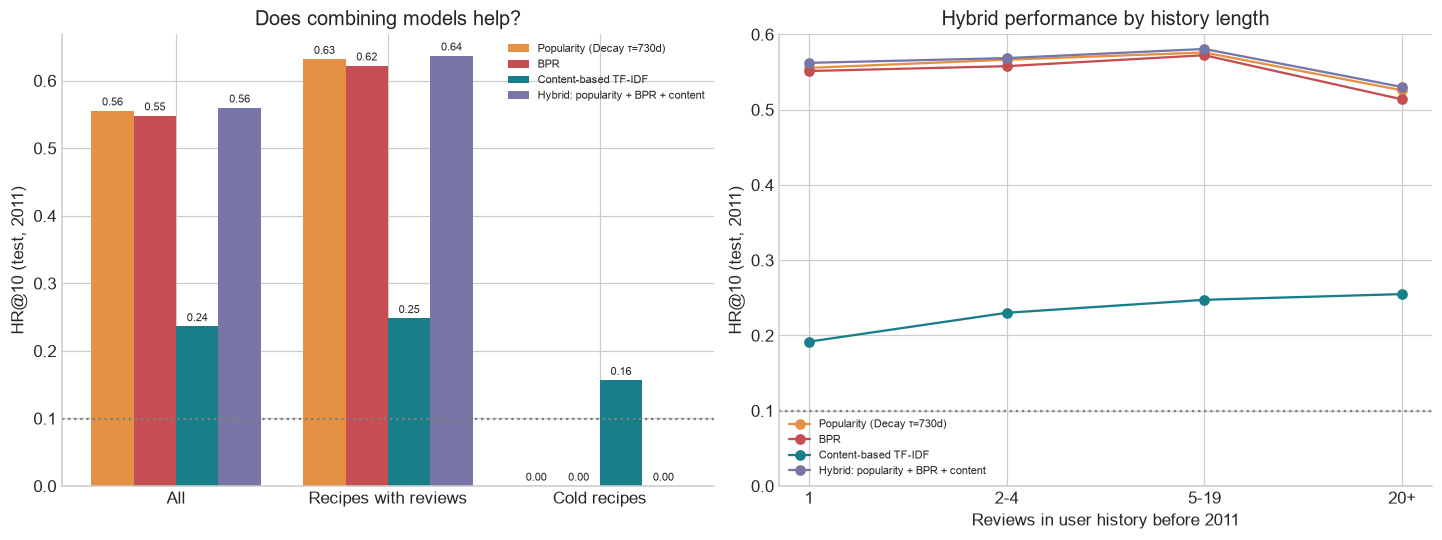

In [48]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

segments = list(SEGMENTS)
x = np.arange(len(segments))
width = 0.8 / len(hybrid_comparison_names)
colors = ['#E59143', '#C44E52', '#187E89', '#7776A6']

for k, (name, color) in enumerate(
    zip(hybrid_comparison_names, colors)
):
    values = (
        hybrid_table.loc[name]
        .reindex(segments)['HR@10']
    )

    bars = axes[0].bar(
        x + (k - 1.5) * width,
        values,
        width,
        label=name,
        color=color
    )
    axes[0].bar_label(
        bars, fmt='%.2f', padding=2, fontsize=7
    )

    per_user = test_results[name].groupby('user_id').agg(
        band=('hist_band', 'first'),
        hr=('HR@10', 'mean')
    )

    by_band = (
        per_user.groupby('band', observed=False)
        .hr.mean()
        .reindex(HIST_BANDS)
    )

    axes[1].plot(
        HIST_BANDS, by_band, 'o-', label=name, color=color
    )

axes[0].set(
    xticks=x,
    xticklabels=['All', 'Recipes with reviews', 'Cold recipes'],
    ylabel='HR@10 (test, 2011)',
    title='Does combining models help?'
)

axes[1].set(
    xlabel='Reviews in user history before 2011',
    ylabel='HR@10 (test, 2011)',
    title='Hybrid performance by history length',
    ylim=(0, None)
)

for ax in axes:
    ax.axhline(10 / 101, ls=':', color='gray')
    ax.legend(fontsize=7)

plt.show()

In [49]:
hybrid_summary = hybrid_table.loc[hybrid_name]

hybrid_summary_lines = [
    "## Summary of Model 5: Combine review patterns and recipe content",
    "",
    "**Weights chosen using validation:**",
    "",
    f"- Popularity: **{best_hybrid_weights['popularity']:.0%}**.",
    f"- BPR: **{best_hybrid_weights['bpr']:.0%}**.",
    f"- Content: **{best_hybrid_weights['content']:.0%}**.",
    "",
    "**Test results:**",
    "",
    f"- Overall HR@10: "
    f"**{hybrid_summary.loc['All', 'HR@10']:.1%}**.",
    f"- HR@10 for recipes with earlier reviews: "
    f"**{hybrid_summary.loc['Warm items', 'HR@10']:.1%}**.",
    f"- HR@10 for cold recipes: "
    f"**{hybrid_summary.loc['Cold items', 'HR@10']:.1%}**.",
    "",
    "**Comparison with popularity:**",
    ""
]

reference = f'Popularity ({best_pop})'

for segment, select in SEGMENTS.items():
    a = test_results[hybrid_name].loc[
        select(test_results[hybrid_name])
    ]
    b = test_results[reference].loc[
        select(test_results[reference])
    ]

    if a.empty:
        continue

    difference, low, high = paired_difference(a, b, 'HR@10')

    if low > 0:
        finding = "The interval supports an improvement."
    elif high < 0:
        finding = "The interval supports worse performance."
    else:
        finding = "The interval includes zero; the difference is unclear."

    hybrid_summary_lines.append(
        f"- **{segment}:** {difference * 100:+.2f} percentage points "
        f"(95% interval: {low * 100:+.2f} to {high * 100:+.2f}). "
        f"{finding}"
    )

if best_hybrid_weights['content'] == 0:
    hybrid_summary_lines.extend([
        "",
        "Validation selected no content contribution. The selected "
        "model therefore does not use ingredients or tags. We should "
        "not claim that this hybrid solves the cold-recipe problem."
    ])
else:
    hybrid_summary_lines.extend([
        "",
        "The selected model uses ingredients and tags alongside "
        "review-based scores. Check the cold-recipe results to see "
        "whether that contribution improves recommendations in practice."
    ])

hybrid_summary_lines.extend([
    "",
    "Scores are converted into ranks within each 101-recipe candidate "
    "list before combining them. The weights are not probabilities, "
    "and results may differ when ranking the entire catalog."
])

show_output(
    MarkdownOutput("\n".join(hybrid_summary_lines))
)

## Summary of Model 5: Combine review patterns and recipe content

**Weights chosen using validation:**

- Popularity: **60%**.
- BPR: **40%**.
- Content: **0%**.

**Test results:**

- Overall HR@10: **56.0%**.
- HR@10 for recipes with earlier reviews: **63.7%**.
- HR@10 for cold recipes: **0.0%**.

**Comparison with popularity:**

- **All:** +0.44 percentage points (95% interval: +0.13 to +0.73). The interval supports an improvement.
- **Warm items:** +0.50 percentage points (95% interval: +0.14 to +0.86). The interval supports an improvement.
- **Cold items:** +0.00 percentage points (95% interval: +0.00 to +0.00). The interval includes zero; the difference is unclear.

Validation selected no content contribution. The selected model therefore does not use ingredients or tags. We should not claim that this hybrid solves the cold-recipe problem.

Scores are converted into ranks within each 101-recipe candidate list before combining them. The weights are not probabilities, and results may differ when ranking the entire catalog.